<a href="https://colab.research.google.com/github/hd77alu/hausa-sentiment-analysis/blob/main/notebook/hausa_sentiment_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Hausa Sentiment Analysis using AfriSenti Dataset**



## **Introduction**

Hausa is one of the most widely spoken native languages in Africa, with over 50 million native speakers and nearly 100 million total speakers across West Africa. Despite its large speaker population, computational resources and specialized NLP tools tailored for Hausa remain under-developed compared to high-resource languages [1].

Sentiment analysis on social media platforms provides crucial insights for public opinion monitoring, brand awareness, public health messaging, and civic engagement. However, applying off-the-shelf English or general multilingual sentiment models directly to Hausa often leads to poor performance due to domain shifts, unique grammatical structures, and informal online expression. This project focuses on building, evaluating, and deploying an end-to-end supervised sentiment classification system for Hausa social media text using the **AfriSenti** dataset [2].

The goal of this project is to automatically classify Hausa tweets into three sentiment categories: **`positive`**, **`neutral`**, or **`negative`**. The system must process real-world noisy social media text, capture regional language nuances, establish strong baselines, fine-tune specialized African-centric pre-trained Transformer architectures, and deploy the optimal model via an interactive web interface.


### Project Objectives

The primary objectives are as follows:

1. Dataset Curation & Preprocessing:
   * Load and audit the **AfriSenti Hausa dataset** (`HausaNLP/AfriSenti-Twitter` / `hau`).
   * Implement text normalization tailored for social media data (stripping URLs, user handles, and special characters while preserving sentiment-bearing expressions and emojis).
   * Perform Exploratory Data Analysis (EDA) on class distribution, sequence lengths, and vocabulary statistics.

2. Models develpment:
   * Construct a classic Machine Learning baseline model using TF-IDF feature extraction paired with SVM.
   * Implement sequential neural architectures (LSTM / GRU).
   * Finetune a transformer model specialized for African context  (AfriBERTa).

3. Systamic Evaluation:
   * Compare model performances using standard evaluation metrics: Accuracy, Precision, Recall, and Macro F1-score.
   * Conduct in-depth qualitative error analysis via confusion matrices to identify patterns in misclassified instances (e.g., subtle neutral text vs. negative sentiment, sarcasm, or out-of-vocabulary words).

4. Web Interface Deployment:
   * Package the best-performing sentiment classifier and deploy an interactive web interface using **Gradio**.
   * Provide direct inference capabilities where users can type or paste Hausa text to receive predicted sentiment probabilities.

### Importing Necessary Libraries

In [ ]:
# CORE UTILITIES
import os
import re
import math
import random
import warnings
import numpy as np
import pandas as pd
import pickle

# Suppress non-critical warnings
warnings.filterwarnings("ignore")

# DATA VISUALIZATION & ANALYSIS
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# HUGGING FACE UTILS
from datasets import  load_dataset, Dataset, DatasetDict

# SICKIT-LEARN
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, precision_recall_curve, average_precision_score
)
from sklearn.preprocessing import label_binarize
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import FeatureUnion

# TENSORFLOW
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, losses, callbacks, regularizers
from tensorflow.keras.layers import TextVectorization

In [ ]:
# Set random seeds for reproducible experiments
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
set_seed(42)

## **Data Invistigation**

### Load Dataset

In [ ]:
# Load the 'hau' (Hausa) subset directly from the masakhane/afrisenti dataset repository
dataset = load_dataset("masakhane/afrisenti", "hau")
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['tweet', 'label'],
        num_rows: 14172
    })
    validation: Dataset({
        features: ['tweet', 'label'],
        num_rows: 2677
    })
    test: Dataset({
        features: ['tweet', 'label'],
        num_rows: 5303
    })
})


In [ ]:
# Extract splits into distinct variables
train_ds = dataset['train']
val_ds = dataset['validation']
test_ds = dataset['test']

# Convert to Pandas DataFrames for easier investigation
train_df = pd.DataFrame(train_ds)
val_df = pd.DataFrame(val_ds)
test_df = pd.DataFrame(test_ds)

print(f"Train set size: {len(train_ds)} rows")
print(f"Validation set size: {len(val_ds)} rows")
print(f"Test set size: {len(test_ds)} rows")

Train set size: 14172 rows
Validation set size: 2677 rows
Test set size: 5303 rows


In [ ]:
# Display the first few rows of the training set
train_df.head()

,tweet,label
0,@user Da kudin da Arewa babu wani abin azo aga...,negative
1,@user Kaga wani Adu ar Banda💔😭 wai a haka Shi ...,negative
2,@user Sai haquri fa yan madrid daman kunce cha...,negative
3,@user Hmmm yanzu kai kasan girman allah daxaka...,negative
4,@user @user Wai gwamno nin Nigeria suna afa kw...,negative


In [ ]:
train_df['tweet'][0]

'@user Da kudin da Arewa babu wani abin azo agani da yayi wa alummah allah ya isa yacucemu wlh yarikitamana kasa yarikitamana kasuwanci harkar ilimi harkar lfy hanyoyi babu lantarki dasuransu komai yalalace ga cinhanci da rashawa a fili ko ina a Nigeria jamiyaryar su tabataman mlm 😭🗣'

In [ ]:
val_df.head()

,tweet,label
0,@user @user Allah ya kai rahmarsa kabarin ta 🤲...,positive
1,@user 🤣🤣🤣 wannan kasa tamu Allah ya kyauta wai...,positive
2,@user Nan da zuwa shekara mai zuwa da yarda Al...,positive
3,"@user Hhm rahama Allah ya shirye ki, a dinga d...",positive
4,@user Innalillahi wainnailaihirraji'un 😢. Alla...,positive


In [ ]:
test_df.head()

,tweet,label
0,ah su rahama za axha madara sa lemu fah mudai ...,positive
1,tohh allah shi taimaka,positive
2,allah ubangiji yakara maka lapia da tsawon ray...,positive
3,wannan shine gaskiyar lamari domin siyasar nig...,positive
4,alhamdulillah allah tabbatar dan isar maulatii...,positive


In [ ]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14172 entries, 0 to 14171
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   tweet   14172 non-null  object
 1   label   14172 non-null  object
dtypes: object(2)
memory usage: 221.6+ KB


In [ ]:
train_df.describe()

,char_length,word_count
count,14172.000000,14172.000000
mean,78.055955,14.015665
std,54.997180,9.655730
min,17.000000,4.000000
25%,40.000000,7.000000
50%,60.000000,11.000000
75%,97.000000,17.000000
max,337.000000,58.000000


In [ ]:
# Investigate label distribution in the training set
print("\nTraining Set Label Distribution:")
label_counts = train_df['label'].value_counts()
label_percentages = train_df['label'].value_counts(normalize=True) * 100

for label, count in label_counts.items():
    print(f"- Label {label}: {count} rows ({label_percentages[label]:.2f}%)")


Training Set Label Distribution:
- Label neutral: 4912 rows (34.66%)
- Label positive: 4687 rows (33.07%)
- Label negative: 4573 rows (32.27%)


### Data Investigation Summary & Insights

Following our initial programmatic exploration of the AfriSenti Hausa (`hau`) dataset, we can synthesize several key characteristics and findings:

#### 1. Dataset Structure & Dimensions (`df.info()`)
*   Train Set (`train_df`): 14,172 rows, featuring two primary raw columns: `tweet` (text of the tweet) and `label` (sentiment target).
*   Validation Set (`val_df`): 2,677 rows.
*   Test Set (`test_df`): 5,303 rows.
*   Data Integrity: There are zero null values in either the tweet texts or their corresponding class labels across all splits.

#### 2. Statistical Text Characteristics (`df.describe()`)
*   Character Length: The average Hausa tweet length is approximately 78 characters (median: 60 characters). Standard deviation is high (~55 characters), indicating a diverse mix of very brief inputs (minimum 17 characters) and highly verbose posts reaching up to 337 characters.
*   Word Count: Tweets average 14 words (median: 11 words). The shortest contains only 4 words, while the longest has 58 words. This suggests that models must handle moderately short, punchy social media sequence lengths.
*   Noise and Context: Initial observation reveals significant presence of web-specific tokens such as Twitter handles (`@user`), emojis (e.g., `💔`, `😭`, `🤲`), and mixed-case structures, suggesting that a dedicated preprocessing/text-cleaning pipeline is essential before training models.

#### 3. Class Balance Analysis
Our label distribution check reveals an exceptionally balanced distribution across all three target sentiment categories in the training data:
*   `neutral`: 4,912 rows (34.66%)
*   `positive`: 4,687 rows (33.07%)
*   `negative`: 4,573 rows (32.27%)

Implication: Because the classes are almost perfectly uniform, we do not need to apply complex class-imbalance countermeasures such as SMOTE, and down-sampling.

### **Exploratory Data Analysis(EDA)**

#### Character Count Boxplot

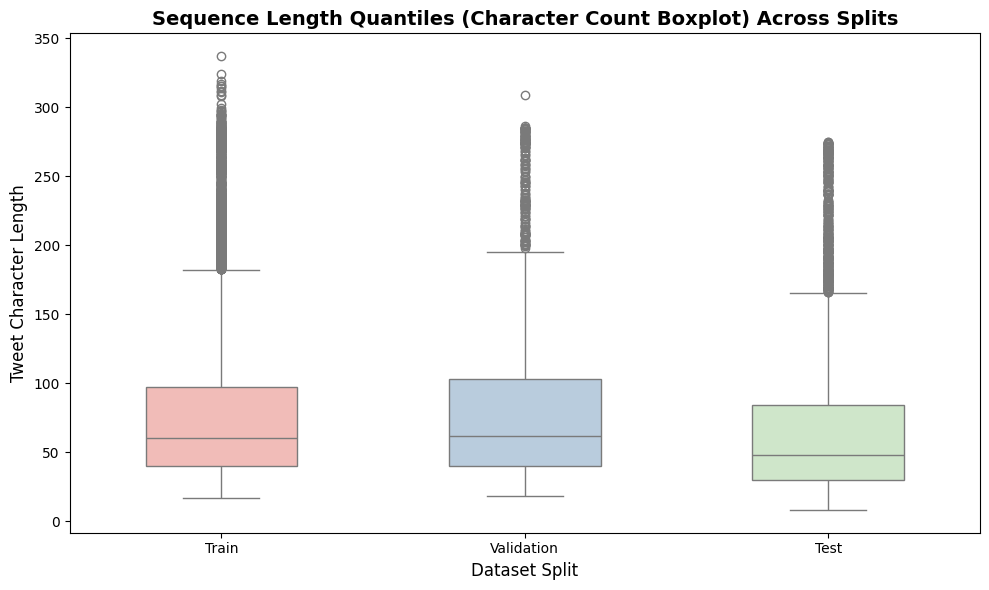

In [ ]:
# Calculate character lengths for all splits
train_df['char_length'] = train_df['tweet'].apply(len)
val_df['char_length'] = val_df['tweet'].apply(len)
test_df['char_length'] = test_df['tweet'].apply(len)

# Combine character counts with split labels for visualization
train_df['split'] = 'Train'
val_df['split'] = 'Validation'
test_df['split'] = 'Test'

combined_df = pd.concat([
    train_df[['char_length', 'split']],
    val_df[['char_length', 'split']],
    test_df[['char_length', 'split']]
], ignore_index=True)

# Create the boxplot visual
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(
    data=combined_df,
    x='split',
    y='char_length',
    palette='Pastel1',
    ax=ax,
    width=0.5
)

ax.set_title("Sequence Length Quantiles (Character Count Boxplot) Across Splits", fontsize=14, fontweight='bold')
ax.set_xlabel("Dataset Split", fontsize=12)
ax.set_ylabel("Tweet Character Length", fontsize=12)

plt.tight_layout()
plt.show()

Analysis (Character Count Boxplot):
* Consistency across Splits: The median, interquartile range (IQR), and overall distribution profile of character lengths are highly uniform across the Train, Validation, and Test splits. This ensures that models trained on the training distribution will generalize well structurally to the validation and testing environments.
* Skewness: The presence of points extending beyond the upper whisker indicates a right-skewed distribution. While most tweets are short (less than 100 characters), a notable number of highly verbose, expressive tweets reach upwards of 250+ characters.

#### Word Count Distribution

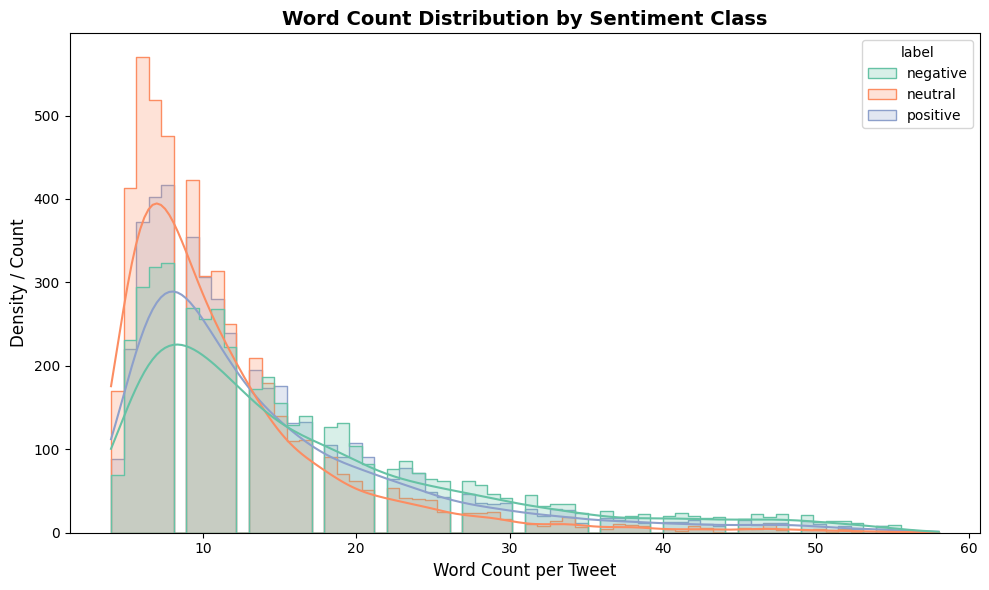

In [ ]:
train_df['word_count'] = train_df['tweet'].apply(lambda x: len(str(x).split()))

# Set up a standalone figure for the word count distribution
fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(
    data=train_df,
    x='word_count',
    hue='label',
    kde=True,
    element='step',
    palette='Set2',
    ax=ax
)

ax.set_title("Word Count Distribution by Sentiment Class", fontsize=14, fontweight='bold')
ax.set_xlabel("Word Count per Tweet", fontsize=12)
ax.set_ylabel("Density / Count", fontsize=12)

plt.tight_layout()
plt.show()

Analysis (Word Count by Sentiment Class):
* Sentiment Symmetry: The overlap in word count distributions indicates that positive, neutral, and negative tweets share a very similar length profile (generally centering around 7 to 15 words per tweet).
* Length-Sentiment Independence: Sentiment intensity in Hausa tweets is not correlated with sentence length. This implies that simpler text classification approaches like TF-IDF or basic sequence embeddings will not suffer from length-induced bias when predicting sentiment.

#### Top 15 Most Frequent Tokens

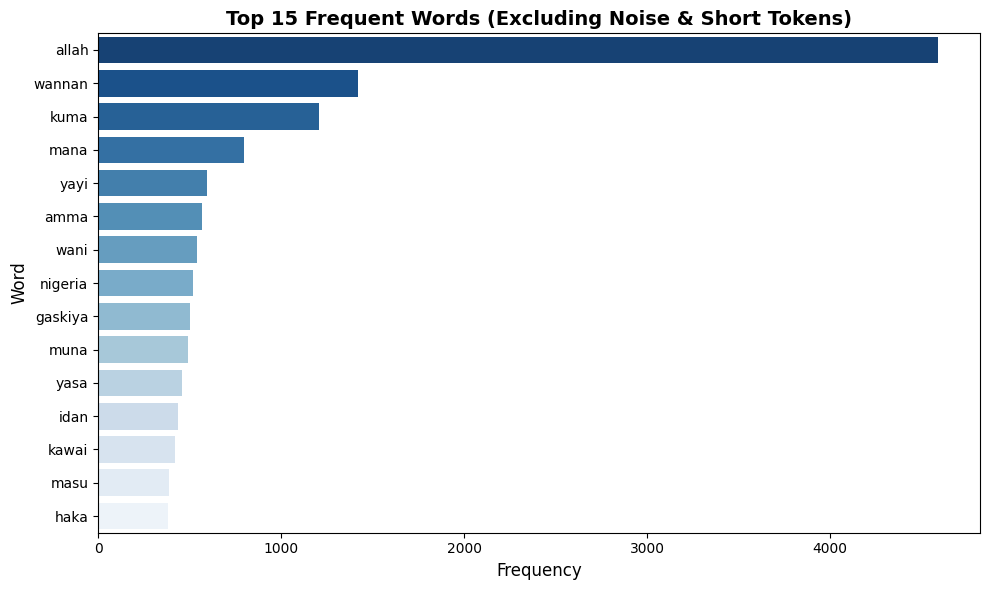

In [ ]:
# Top 15 Most Frequent Tokens in Training Corpus
all_words = ' '.join(train_df['tweet']).lower().split()
# Simple noise filter for quick frequency plot
filtered_words = [w for w in all_words if len(w) > 3 and not w.startswith('http') and not w.startswith('@')]
top_words = Counter(filtered_words).most_common(15)

words_df = pd.DataFrame(top_words, columns=['Word', 'Frequency'])

# Set up a standalone figure
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=words_df,
    y='Word',
    x='Frequency',
    palette='Blues_r',
    ax=ax
)

ax.set_title("Top 15 Frequent Words (Excluding Noise & Short Tokens)", fontsize=14, fontweight='bold')
ax.set_xlabel("Frequency", fontsize=12)
ax.set_ylabel("Word", fontsize=12)
plt.tight_layout()
plt.show()

Analysis (Top 15 Most Frequent Tokens):
* Dominance of Religious and Cultural Terms: The token *'allah'* is by far the most frequent term in the entire corpus. In Hausa social media text, religious references and invocations (e.g., *'Allah yayi'*, *'Allah sarki'*) are highly prevalent. Recognizing this is crucial because the word *'allah'* can appear across positive, neutral, and negative contexts.
* Linguistic Demographics & Structure: Standard function words (*'wannan'*, *'kuma'*, *'mana'*, *'haka'*) alongside regional nouns (*'nigeria'*) represent core vocabularies. We must keep them to preserve semantic and syntactic contexts.

## **Data Preprocessing**

To clean and prepare the noisy Twitter dataset for both classic machine learning and deep learning models, we executed a highly targeted, customized text normalization pipeline:

*   **HTML Entity Removal:** Stripped legacy web remnants (such as `&amp;`, `&lt;`) that do not carry semantic weight.
*   **Handle Redaction:** Removed anonymous Twitter handles (`@user`) to prevent models from overfitting to user-tag patterns.
*   **URL/Hyperlink Extraction:** Cleaned standard web protocols (`http`, `https`, `www`) to reduce vocabulary noise.
*   **Apostrophe Normalization:** Normalized variant and curly typographic apostrophes (such as `’`, `ʼ`, and `‘`) into standardized straight apostrophes (`'`). This prevents contractions and regional Hausa glottal markers from being fragmented or treated as distinct out-of-vocabulary tokens.
*   **Invisible Character Stripping:** Eliminated silent, non-renderable characters like emoji variation selectors (`\ufe0f`) and zero-width joiners (`\u200d`) right before spacing emojis to prevent empty/junk tokens.
*   **Emoji Modifier Filtering:** Automatically stripped skin tone indicators (`\U0001F3FB-\U0001F3FF`) and gender signifiers (`\u2640`, `\u2642`) to standardize emojis to their base form (e.g., converting custom-shaded or gendered variations back to standard base representations like `👍` or `🤷`).
*   **Flag and Emoji Isolation:** Isolated multi-indicator flags (such as `🇳🇬`) and individual emotional emojis by adding space boundaries, ensuring that they are parsed as standalone semantic features by downstream sequence vectorizers.
*   **Custom Text Standardization:** Configured a custom standardization function for our neural vectorizer layer that filters out standard punctuation but explicitly preserves normalized straight apostrophes.
*   **Whitespace Normalization:** Condensed redundant line breaks, tabs, and duplicate spaces into single-spaced structures.

In [ ]:
# Compile regular expression patterns to identify emojis, skin tone colors, gender symbols, and 2-letter country flags
SKIN_TONE = re.compile("[\U0001F3FB-\U0001F3FF]")
GENDER    = re.compile("[\u2640\u2642]")
FLAG      = re.compile("[\U0001F1E6-\U0001F1FF]{2}")
EMOJI     = re.compile("[\U0001F300-\U0001FAFF\u2600-\u27BF\u2B00-\u2BFF]")

def clean_tweet(text):
    if not isinstance(text, str):
        return ""
    # Remove HTML entities
    text = re.sub(r"&[a-z]+;", "", text)
    # Remove Twitter handles (@user)
    text = re.sub(r"@[A-Za-z0-9_]+", "", text)
    # Remove URLs/Hyperlinks (including dangling http: or https:)
    text = re.sub(r"https?:\/\/\S+|www\.\S+|https?:?", "", text)
    # Normalize curly apostrophes to straight apostrophes
    text = re.sub(r"[’ʼ‘]", "'", text)

    # Emoji/Modifier Cleaning
    text = text.replace("\ufe0f", "").replace("\u200d", "")   # Strip invisible selectors/joiners
    text = SKIN_TONE.sub("", text)                            # Strip skin tones
    text = GENDER.sub("", text)                               # Strip gender modifiers
    text = FLAG.sub(lambda m: f" {m.group()} ", text)         # Spaced-out 2-letter flags
    text = EMOJI.sub(lambda m: f" {m.group()} ", text)        # Spaced-out other emojis

    # Replace multiple whitespaces and newlines with a single space
    text = re.sub(r"\s+", " ", text)
    return text.strip()

# Apply preprocessing to all DataFrames
train_df['cleaned_tweet'] = train_df['tweet'].apply(clean_tweet)
val_df['cleaned_tweet'] = val_df['tweet'].apply(clean_tweet)
test_df['cleaned_tweet'] = test_df['tweet'].apply(clean_tweet)

# Update Hugging Face dataset splits with the cleaned tweets
train_ds = train_ds.map(lambda x: {"cleaned_tweet": clean_tweet(x["tweet"])})
val_ds = val_ds.map(lambda x: {"cleaned_tweet": clean_tweet(x["tweet"])})
test_ds = test_ds.map(lambda x: {"cleaned_tweet": clean_tweet(x["tweet"])})
dataset = DatasetDict({"train": train_ds, "validation": val_ds, "test": test_ds})

# Display sample comparisons to verify the cleaning process
print("Preprocessing complete! Sample comparison:")
for i in range(3):
    print(f"\nOriginal [{i}]: {train_df['tweet'].iloc[i]}")
    print(f"Cleaned  [{i}]: {train_df['cleaned_tweet'].iloc[i]}")

Map:   0%|          | 0/14172 [00:00<?, ? examples/s]

Map:   0%|          | 0/2677 [00:00<?, ? examples/s]

Map:   0%|          | 0/5303 [00:00<?, ? examples/s]

Preprocessing complete! Sample comparison:

Original [0]: @user Da kudin da Arewa babu wani abin azo agani da yayi wa alummah allah ya isa yacucemu wlh yarikitamana kasa yarikitamana kasuwanci harkar ilimi harkar lfy hanyoyi babu lantarki dasuransu komai yalalace ga cinhanci da rashawa a fili ko ina a Nigeria jamiyaryar su tabataman mlm 😭🗣
Cleaned  [0]: Da kudin da Arewa babu wani abin azo agani da yayi wa alummah allah ya isa yacucemu wlh yarikitamana kasa yarikitamana kasuwanci harkar ilimi harkar lfy hanyoyi babu lantarki dasuransu komai yalalace ga cinhanci da rashawa a fili ko ina a Nigeria jamiyaryar su tabataman mlm 😭 🗣

Original [1]: @user Kaga wani Adu ar Banda💔😭 wai a haka Shi ne shugaban sojoji.... Gaskiya Buhari kaci Amanan mu da kasa wannan mutum ah wajen nan
Cleaned  [1]: Kaga wani Adu ar Banda 💔 😭 wai a haka Shi ne shugaban sojoji.... Gaskiya Buhari kaci Amanan mu da kasa wannan mutum ah wajen nan

Original [2]: @user Sai haquri fa yan madrid daman kunce champion din ya 

### Preprocessing Check

In [ ]:
for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    s = df["cleaned_tweet"]
    print(name,
          "| empty:", (s.str.len() == 0).sum(),
          "| leftover @:", s.str.contains("@").sum(),
          "| leftover http:", s.str.contains("http").sum(),
          "| apostrophe variants:", s.str.contains("[’ʼ‘]").sum())

# Which non-ASCII characters remain? Hausa hooked letters (ɓ ɗ ƙ) should show up; anything else weird deserves a look.
from collections import Counter
chars = Counter(ch for t in train_df["cleaned_tweet"] for ch in t if ord(ch) > 127)
print(chars.most_common(40))

train | empty: 0 | leftover @: 0 | leftover http: 0 | apostrophe variants: 0
val | empty: 0 | leftover @: 0 | leftover http: 0 | apostrophe variants: 0
test | empty: 0 | leftover @: 0 | leftover http: 0 | apostrophe variants: 0
[('😂', 5703), ('🤣', 2181), ('🙏', 2168), ('😭', 2044), ('🤔', 1211), ('🙄', 945), ('🤲', 707), ('😏', 639), ('😁', 638), ('😎', 596), ('😅', 499), ('😀', 493), ('😡', 443), ('😢', 392), ('😠', 372), ('👌', 355), ('👏', 339), ('🇳', 328), ('👍', 328), ('😍', 312), ('🇬', 303), ('💯', 303), ('🏃', 262), ('😄', 260), ('😥', 247), ('🚶', 247), ('❤', 240), ('💪', 221), ('💔', 219), ('ƙ', 219), ('😊', 216), ('🔥', 208), ('😆', 199), ('😃', 195), ('😒', 191), ('🙌', 182), ('🤷', 173), ('🤗', 163), ('ɗ', 159), ('😜', 157)]


## **Models Training**

### Evaluation & Visualization Helper Functions

To ensure rigorous and reproducible evaluation across all models (Machine Learning baseline, sequence models, and Transformers), we have implemented a suite of modular helper functions:

1.  **`evaluate_model_performance(y_true, y_pred, y_probs)`**
    *   **Purpose:** Computes standard classification metrics.
    *   **Metrics Included:** Accuracy, Weighted Precision, Weighted Recall, Weighted F1-Score, and One-vs-Rest (OVR) ROC-AUC (when probability predictions are supplied).
    *   **Output:** Returns a neatly structured pandas DataFrame to easily compare performances across multiple models.

2.  **`plot_learning_curve(history)`**
    *   **Purpose:** Monitors training diagnostics for deep learning models.
    *   **Output:** Generates side-by-side epoch-wise curves comparing training vs. validation loss and training vs. validation accuracy to easily detect overfitting or convergence issues.

3.  **`plot_confusion_matrix(y_true, y_pred, class_names)`**
    *   **Purpose:** Performs granular visual error analysis.
    *   **Output:** Produces a heatmap indicating both raw instance counts and percentage distributions per class, showing where the models confuse sentiment (e.g., mistaking `negative` text for `neutral`).

4.  **`plot_precision_recall_curve(y_true, y_probs, class_names)`**
    *   **Purpose:** Evaluates model robustness across different decision thresholds.
    *   **Output:** Visualizes Precision-Recall curves individually for each of the three sentiment classes (`positive`, `neutral`, `negative`) along with their Average Precision (AP) scores.

In [ ]:
# Map text labels to numerical categories
class_names = ['negative', 'neutral', 'positive']
label_mapping = {'negative': 0, 'neutral': 1, 'positive': 2}
y_train = train_df['label'].map(label_mapping).values
y_val = val_df['label'].map(label_mapping).values
y_test = test_df['label'].map(label_mapping).values

# EVALUATE MODEL PERFORMANCE
def evaluate_model_performance(y_true, y_pred, y_probs=None, class_names=None, model_name="Model"):
    """
    Computes accuracy, precision, recall, F1-score, and ROC-AUC,
    returning the metrics cleanly in a pandas DataFrame.
    """
    # Calculate standard metrics (weighted average handles class distribution well)
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)

    # Calculate ROC-AUC if probability scores/logits are provided
    auc_val = np.nan
    if y_probs is not None:
        try:
            n_classes = len(np.unique(y_true))
            if n_classes == 2:
                # Binary classification
                auc_val = roc_auc_score(y_true, y_probs[:, 1])
            else:
                # Multi-class (3 classes): One-vs-Rest AUC
                y_true_bin = label_binarize(y_true, classes=range(n_classes))
                auc_val = roc_auc_score(y_true_bin, y_probs, multi_class='ovr', average='weighted')
        except Exception as e:
            print(f"Note: Could not calculate AUC ({e})")

    metrics_df = pd.DataFrame({
        "Model": [model_name],
        "Accuracy": [acc],
        "Precision (Weighted)": [prec],
        "Recall (Weighted)": [rec],
        "F1-Score (Weighted)": [f1],
        "AUC (OVR)": [auc_val]
    })

    return metrics_df.round(4)

# PLOT LEARNING CURVE

def plot_learning_curve(history, title="Model Learning Curve"):
    """
    Plots training vs validation Accuracy and Loss from a Keras History object.
    """
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    epochs = range(1, len(history.history['loss']) + 1)

    # --- Loss Plot ---
    axes[0].plot(epochs, history.history['loss'], label='Train Loss', marker='o')
    if 'val_loss' in history.history:
        axes[0].plot(epochs, history.history['val_loss'], label='Val Loss', marker='o')
    axes[0].set_title(f"{title} - Loss", fontsize=12, fontweight='bold')
    axes[0].set_xlabel("Epochs")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(True)

    # --- Accuracy Plot ---
    acc_key = 'accuracy' if 'accuracy' in history.history else 'acc'
    val_acc_key = 'val_accuracy' if 'val_accuracy' in history.history else 'val_acc'

    axes[1].plot(epochs, history.history[acc_key], label='Train Accuracy', marker='o')
    if val_acc_key in history.history:
        axes[1].plot(epochs, history.history[val_acc_key], label='Val Accuracy', marker='o')
    axes[1].set_title(f"{title} - Accuracy", fontsize=12, fontweight='bold')
    axes[1].set_xlabel("Epochs")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

# PLOT CONFUSION MATRIX
def plot_confusion_matrix(y_true, y_pred, class_names, title="Confusion Matrix", cmap="Blues"):
    """
    Plots a normalized and raw confusion matrix heat map using Seaborn.
    """
    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    plt.figure(figsize=(7, 5))

    # Annotate with count and percentage
    annot_matrix = np.empty_like(cm, dtype=object)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            annot_matrix[i, j] = f"{cm[i, j]}\n({cm_norm[i, j]:.1%})"

    sns.heatmap(
        cm,
        annot=annot_matrix,
        fmt="",
        cmap=cmap,
        xticklabels=class_names,
        yticklabels=class_names,
        cbar=True
    )

    plt.title(title, fontsize=13, fontweight='bold')
    plt.xlabel("Predicted Label", fontsize=11)
    plt.ylabel("True Label", fontsize=11)
    plt.tight_layout()
    plt.show()

# PLOT PRECISION-RECALL CURVE
def plot_precision_recall_curve(y_true, y_probs, class_names, title="Precision-Recall Curve"):
    """
    Plots Precision-Recall curves for each sentiment class in a multi-class setting.
    """
    plt.figure(figsize=(8, 6))
    n_classes = len(class_names)
    y_true_bin = label_binarize(y_true, classes=range(n_classes))

    for i in range(n_classes):
        precision, recall, _ = precision_recall_curve(y_true_bin[:, i], y_probs[:, i])
        ap_score = average_precision_score(y_true_bin[:, i], y_probs[:, i])
        plt.plot(recall, precision, lw=2, label=f"{class_names[i]} (AP = {ap_score:.2f})")

    plt.title(title, fontsize=13, fontweight='bold')
    plt.xlabel("Recall", fontsize=11)
    plt.ylabel("Precision", fontsize=11)
    plt.legend(loc="lower left")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

### **TF-IDF + Support Vector Machine (SVM)**

We will construct the following pipeline:
*   `TfidfVectorizer`: Configured to capture both unigrams and bigrams (`ngram_range=(1, 2)`) to preserve short local phrasing dependencies.
*   `LinearSVC`: A robust, high-performance Support Vector Machine classifier suited for sparse, high-dimensional text vectors.

*Note: To generate probability estimates for the Precision-Recall curves and ROC-AUC metrics, we wrap the trained `LinearSVC` within a `CalibratedClassifierCV`.*

In [ ]:
# Define the pipeline components
svm_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), max_features=15000, sublinear_tf=True)),
    ('svm', LinearSVC(C=1.0, random_state=42))
])

# Wrap model to get probability predictions for advanced evaluation
calibrated_svm = CalibratedClassifierCV(estimator=svm_pipeline, cv='prefit')

# Fit baseline model on the cleaned tweets
svm_pipeline.fit(train_df['cleaned_tweet'], y_train)
calibrated_svm.fit(train_df['cleaned_tweet'], y_train)

# Generate predictions for the validation split
val_predictions = svm_pipeline.predict(val_df['cleaned_tweet'])
val_probabilities = calibrated_svm.predict_proba(val_df['cleaned_tweet'])

print("Baseline SVM training and calibration complete!")

Baseline SVM training and calibration complete!


#### Evaluation Metrics

In [ ]:
# Compute & display model metrics using evaluate_model_performance helper
svm_metrics = evaluate_model_performance(
    y_true=y_val,
    y_pred=val_predictions,
    y_probs=val_probabilities,
    class_names=class_names,
    model_name="TF-IDF + Linear SVM"
)
display(svm_metrics)

,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted),AUC (OVR)
0,TF-IDF + Linear SVM,0.7337,0.7363,0.7337,0.7345,0.8908


#### TF-IDF + Support Vector Machine (SVM) Evaluation Metrics Insights
*   **Accuracy & F1-Score:** The model achieves a solid baseline validation accuracy of **73.37%** and a weighted F1-score of **73.45%**. For a three-class sentiment task on noisy social media text, this represents a strong, stable initial benchmark.
*   **Area Under the Curve (AUC):** The One-vs-Rest AUC is outstanding at **0.8908**. This indicates that the calibrated model possesses a very high discriminative capability, successfully distinguishing correct classes at various decision thresholds despite the simple n-gram representation.

#### Precision-Recall curve

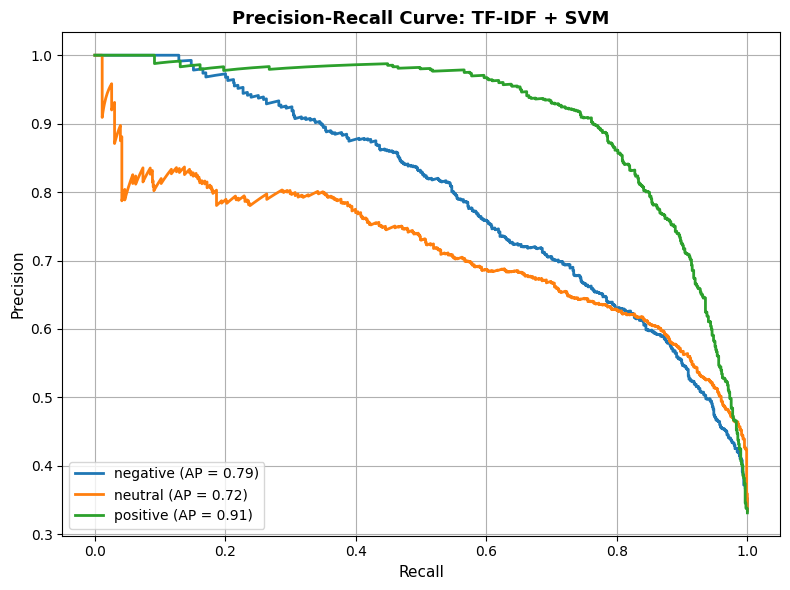

In [ ]:
# Plot multi-class Precision-Recall curves
plot_precision_recall_curve(
    y_true=y_val,
    y_probs=val_probabilities,
    class_names=class_names,
    title="Precision-Recall Curve: TF-IDF + SVM"
)

#### TF-IDF + Support Vector Machine (SVM) Precision-Recall Curve Insights
*   **Robustness per Class:** The Average Precision (AP) scores reflect the model's reliability across different classes:
    *   `positive` achieves the highest AP of **0.91**, indicating highly reliable positive lexical indicators.
    *   `negative` follows closely with an AP of **0.79**.
    *   `neutral` exhibits the lowest AP of **0.72**, showing that the baseline model struggles to maintain high precision as recall increases for neutral text.

#### Confusion Matrix

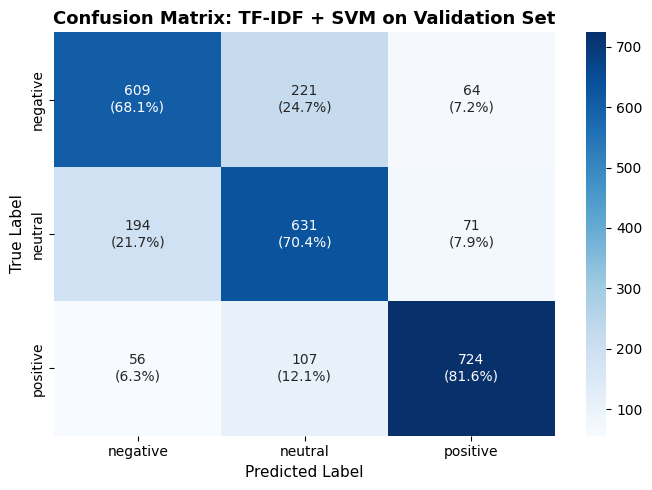

In [ ]:
# Plot confusion matrix showing class transition patterns
plot_confusion_matrix(
    y_true=y_val,
    y_pred=val_predictions,
    class_names=class_names,
    title="Confusion Matrix: TF-IDF + SVM on Validation Set"
)

#### TF-IDF + Support Vector Machine (SVM) Confusion Matrix Insights
*   **Sentiment Symmetry:** Looking at the normalized diagonal, the model performs with relatively balanced recall across classes: `positive` (81.6%), `negative` (70.4%), and `neutral` (68.1%).
*   **Neutral Class Vulnerability:** The `neutral` class is the most difficult to classify. Specifically, **21.7%** of truly neutral tweets are misclassified as negative, and **7.9%** are misclassified as positive. This is typical in social media sentiment tasks, as objective observations or queries often share structural similarities or common keywords (such as "Allah") with positive and negative expressions.
*   **Strong Positive-Negative Separation:** Crucially, the model rarely confuses opposite extremes: only **7.2%** of negative tweets are misclassified as positive, and only **6.3%** of positive tweets are misclassified as negative.

### **Experiment 1: Word + Character Sub-Word Feature Union**

To overcome these limitations without moving to resource-intensive deep learning models yet, we can execute **Experiment 2**: extracting features at both the **word** and **character sub-word** levels simultaneously.

By extracting character n-grams (e.g., sequences of 3 to 5 characters), the model can:
* Capture common roots, prefixes, and suffixes.
* Maintain robust representations for typos and unseen spelling variations.
* Model word structures even when formal token boundaries are messy.

In [ ]:
# Configure a hybrid vectorizer pipeline
hybrid_vectorizer = FeatureUnion([
    # Feature 1: Standard word-level n-grams (1 to 2 words)
    ('word_char', TfidfVectorizer(
        analyzer='word',
        ngram_range=(1, 2),
        max_features=10000,
        sublinear_tf=True
    )),
    # Feature 2: Sub-word character-level n-grams (3 to 5 characters)
    ('subword_char', TfidfVectorizer(
        analyzer='char',
        ngram_range=(3, 5),
        max_features=25000,
        sublinear_tf=True
    ))
])

# Build the new pipeline containing our hybrid feature union
hybrid_pipeline = Pipeline([
    ('features', hybrid_vectorizer),
    ('svm', LinearSVC(C=0.5, random_state=42, class_weight='balanced'))
])

# Calibrate the hybrid model for probability estimates
calibrated_hybrid_svm = CalibratedClassifierCV(estimator=hybrid_pipeline, cv=3)

# Train the hybrid model
print("Training Hybrid Word/Character N-Gram SVM...")
calibrated_hybrid_svm.fit(train_df['cleaned_tweet'], y_train)

# Predict on validation data
hybrid_val_preds = calibrated_hybrid_svm.predict(val_df['cleaned_tweet'])
hybrid_val_probs = calibrated_hybrid_svm.predict_proba(val_df['cleaned_tweet'])

print("Hybrid Model Training and Predictions Complete!")

Training Hybrid Word/Character N-Gram SVM...
Hybrid Model Training and Predictions Complete!


#### Evaluation Metrics

In [ ]:
# Evaluate performance metrics of the hybrid model
hybrid_metrics = evaluate_model_performance(
    y_true=y_val,
    y_pred=hybrid_val_preds,
    y_probs=hybrid_val_probs,
    class_names=class_names,
    model_name="TF-IDF (Word + Char) + SVM"
)

# Combine and compare our baseline with the new hybrid experiment
full_comparison_df = pd.concat([svm_metrics, hybrid_metrics], ignore_index=True)
display(full_comparison_df)

,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted),AUC (OVR)
0,TF-IDF + Linear SVM,0.7337,0.7363,0.7337,0.7345,0.8908
1,TF-IDF (Word + Char) + SVM,0.7751,0.7807,0.7751,0.7762,0.9181


#### Hybrid (Word + Char) Evaluation Metrics Insights
*   **Performance Jump (Accuracy & F1-Score):** Integrating sub-word character features yielded a massive boost in performance over the baseline. Validation accuracy increased from **73.37% to 77.51%** (+4.14% absolute), and the weighted F1-score rose from **73.45% to 77.62%** (+4.17% absolute).
*   **Enhanced Class Discriminability:** The One-vs-Rest AUC rose significantly from **0.8908 to 0.9181** (+0.0273). This indicates that sub-word structures make the features far more linearly separable, allowing the classifier to separate sentiment boundaries cleanly at various confidence thresholds.

#### Precision-Recall Curve

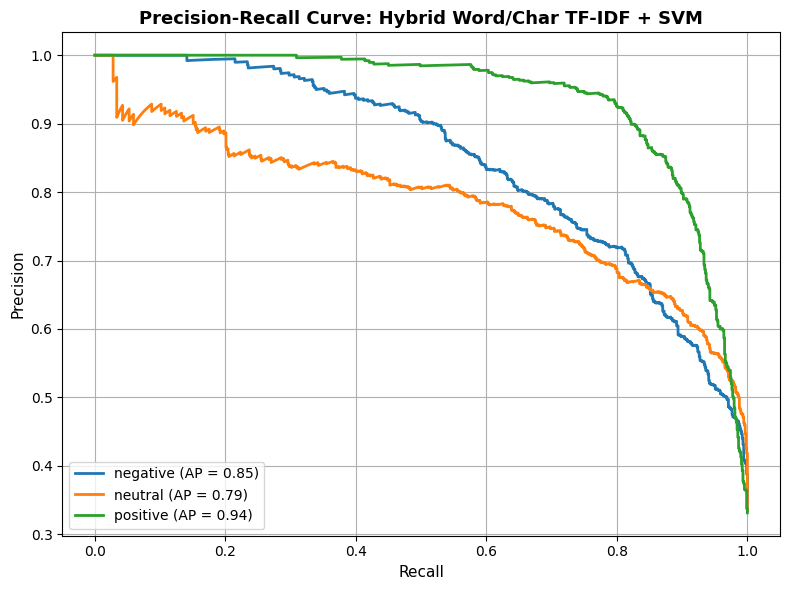

In [ ]:
# Plot multi-class Precision-Recall curves for the Hybrid (Word + Char) model
plot_precision_recall_curve(
    y_true=y_val,
    y_probs=hybrid_val_probs,
    class_names=class_names,
    title="Precision-Recall Curve: Hybrid Word/Char TF-IDF + SVM"
)

#### Hybrid (Word + Char) Precision-Recall Curve Insights
*   **Systemic AP Gains:** Comparing the Average Precision (AP) curves, we observe an across-the-board expansion of precision at higher levels of recall:
    *   `positive` sentiment remains our most robust category, with its AP climbing from **0.91 to 0.94**.
    *   `negative` sentiment AP leaped from **0.79 to 0.85**.
    *   `neutral` sentiment, previously our weakest point at **0.72**, saw a substantial reliability boost, climbing to an AP of **0.79**. This indicates that sub-word sub-components significantly reduce false alarms for neutral phrasing.

#### Confusion Matrix

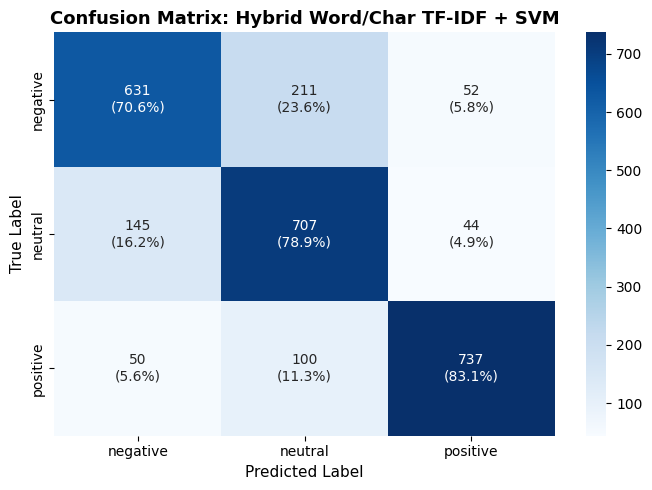

In [ ]:
# Plot the updated confusion matrix for our hybrid model
plot_confusion_matrix(
    y_true=y_val,
    y_pred=hybrid_val_preds,
    class_names=class_names,
    title="Confusion Matrix: Hybrid Word/Char TF-IDF + SVM"
)

#### Hybrid (Word + Char) Confusion Matrix Insights
*   **Substantial Neutral Class Recovery:** The main target of this experiment was the vulnerable `neutral` class. By capturing character-level patterns, true neutral recall rose from **70.4% to 78.9%**. Most notably, neutral tweets misclassified as negaitive fell from **21.7% down to 16.2%**.
*   **Class Error Shrinkage:** The model's recognition of the extreme classes also tightened:
    *   True negative recall increased from **68.1% to 70.6%**.
    *   True positive recall improved from **81.6% to 83.1%**.
*   **Extremely Low Polarity Confusion:** Symmetrical cross-polarity confusion remains negligible. Only **5.8%** of negative tweets were predicted as positive, and only **5.6%** of positive tweets were predicted as negative, proving that morphological sub-word structures keep opposites distinct in the vector space.

## **Sequential Neural Network Models**

#### Text Vectorization

In [ ]:
# Text Vectorization Configuration
MAX_VOCAB_SIZE = 20000
MAX_SEQUENCE_LENGTH = 60 # (Max Length of 60 Covers 100%)
EMBEDDING_DIM = 128
NUM_CLASSES = 3

def standardize(x):
    x = tf.strings.lower(x)
    # Remove standard punctuation but explicitly keep apostrophes
    return tf.strings.regex_replace(x, r"[!\"#$%&()*+,\-./:;<=>?@\[\\\]^_`{|}~]", " ")

# Text Vectorization with custom standardization
vectorizer_layer = layers.TextVectorization(
    max_tokens=MAX_VOCAB_SIZE,
    standardize=standardize,
    output_mode='int',
    output_sequence_length=MAX_SEQUENCE_LENGTH
)

# Adapt vectorizer on cleaned training tweets
vectorizer_layer.adapt(train_df['cleaned_tweet'].values)
actual_vocab_size = len(vectorizer_layer.get_vocabulary())
print(f"Vocabulary successfully adapted. Total Vocabulary Size: {actual_vocab_size:,}")

Vocabulary successfully adapted. Total Vocabulary Size: 20,000


### **LSTM Baseline**

In [ ]:
# Define the LSTM Architecture
def build_lstm_model(vocab_size, embedding_dim, seq_len, num_classes=3):
    model = models.Sequential([
        layers.Input(shape=(1,), dtype=tf.string),
        vectorizer_layer,
        layers.Embedding(
            input_dim=vocab_size,
            output_dim=embedding_dim,
            mask_zero=True
        ),
        layers.LSTM(64),
        layers.Dense(64, activation='relu'),
        layers.Dense(num_classes, activation='softmax')
    ], name="Baseline_LSTM")

    return model

# Instantiate and Compile Model
lstm_model = build_lstm_model(
    vocab_size=actual_vocab_size,
    embedding_dim=EMBEDDING_DIM,
    seq_len=MAX_SEQUENCE_LENGTH,
    num_classes=NUM_CLASSES
)

lstm_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss=losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

lstm_model.summary()

Model: "Baseline_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ (None, 60)             │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 60, 128)        │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,613,763 (9.97 MB)

 Trainable params: 2,613,763 (9.97 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train the Model
early_stop = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

history = lstm_model.fit(
    train_df['cleaned_tweet'].values,
    y_train,
    epochs=15,
    batch_size=32,
    validation_data=(val_df['cleaned_tweet'].values, y_val),
    callbacks=[early_stop]
)

Epoch 1/15
443/443 ━━━━━━━━━━━━━━━━━━━━ 21s 44ms/step - accuracy: 0.6711 - loss: 0.7408 - val_accuracy: 0.7411 - val_loss: 0.6088
Epoch 2/15
443/443 ━━━━━━━━━━━━━━━━━━━━ 19s 41ms/step - accuracy: 0.8373 - loss: 0.4237 - val_accuracy: 0.7206 - val_loss: 0.7361
Epoch 3/15
443/443 ━━━━━━━━━━━━━━━━━━━━ 22s 44ms/step - accuracy: 0.9202 - loss: 0.2368 - val_accuracy: 0.7325 - val_loss: 0.8321
Epoch 4/15
443/443 ━━━━━━━━━━━━━━━━━━━━ 21s 47ms/step - accuracy: 0.9539 - loss: 0.1443 - val_accuracy: 0.7198 - val_loss: 1.0138
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 1.


#### Evaluation Metrics

In [ ]:
# Evaluate Model Performance
lstm_val_probs = lstm_model.predict(val_df['cleaned_tweet'].values)
lstm_val_preds = np.argmax(lstm_val_probs, axis=1)

lstm_metrics = evaluate_model_performance(
    y_true=y_val,
    y_pred=lstm_val_preds,
    y_probs=lstm_val_probs,
    class_names=class_names,
    model_name="Baseline LSTM"
)
display(lstm_metrics)

84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step


,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted),AUC (OVR)
0,Baseline LSTM,0.7411,0.7411,0.7411,0.7406,0.8905


#### Baseline LSTM Evaluation Metrics Insights
* **Performance Compared to SVM:** The baseline unidirectional LSTM model achieves a validation accuracy of **74.11%** and a weighted F1-score of **74.01%**. This is slightly lower than our raw TF-IDF + Linear SVM baseline (**73.37%** accuracy) and significantly below our hybrid word/char SVM (**77.18%** accuracy).
* **High Discriminative Potential (AUC):** Despite the lower accuracy, the LSTM yields an AUC of **0.8905**, indicating excellent overall probability separation. This suggests that with proper regularization, optimization, or pre-trained embeddings, sequential architectures hold strong promise.

#### Learning Curve

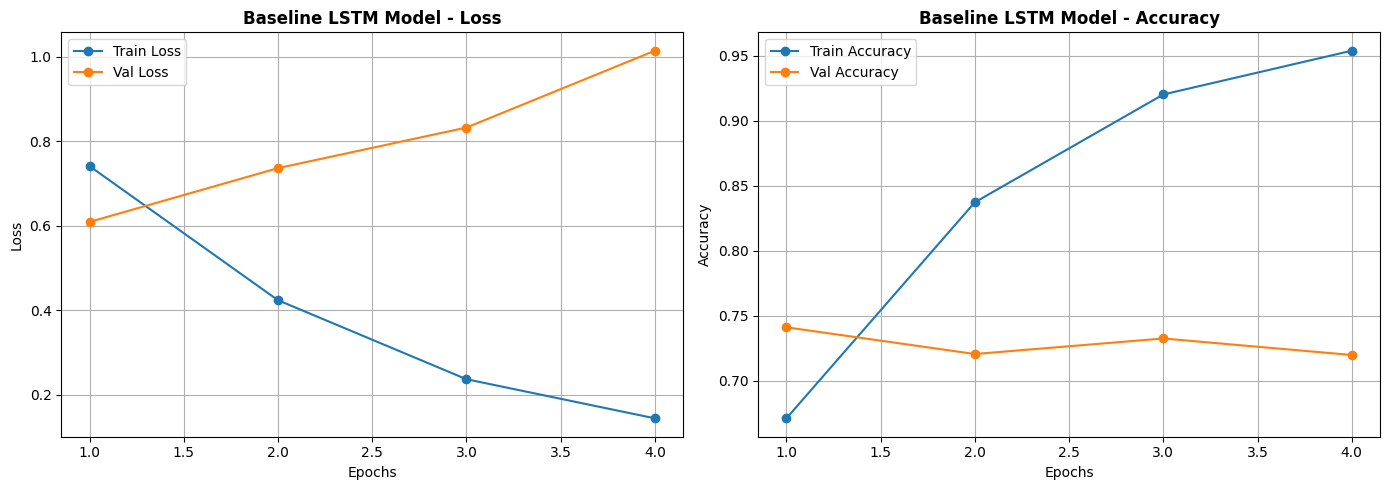

In [ ]:
plot_learning_curve(history, title="Baseline LSTM Model")

#### Baseline LSTM Learning Curve Insights
* **Severe Overfitting:** The learning curves clearly display classic overfitting behavior. While training accuracy rapidly approaches **~95%** and training loss drops to **~0.04**, the validation accuracy plateaus around **72-74%** and validation loss begins to climb significantly after the first epoch.
* **The Need for Regularization:** Because we don't have regularization (dropout, recurrent dropout, spatial dropout) to study this baseline, the model quickly memorized the training corpus. Adding dropout layers or utilizing early stopping with a tighter patience window will be critical next steps to stabilize learning.

#### Precision-Recall curves

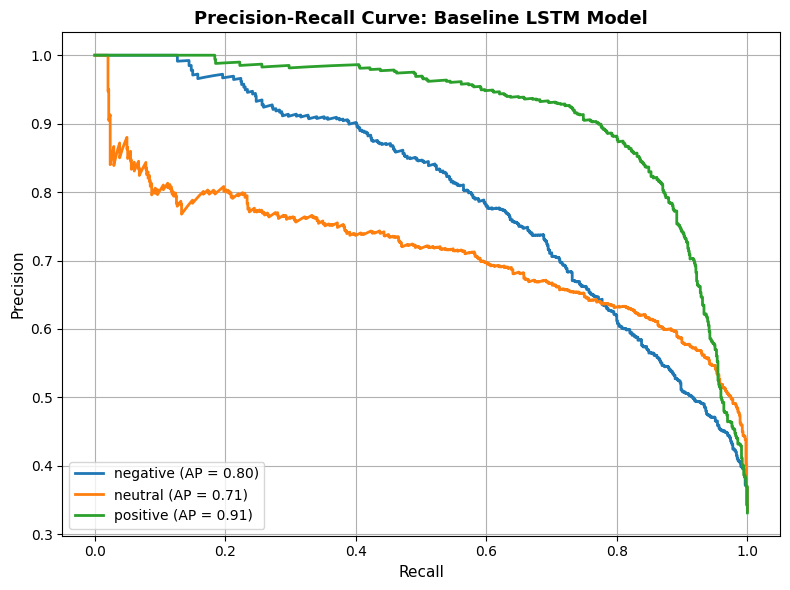

In [ ]:
# Plot multi-class Precision-Recall curves for the Baseline LSTM model
plot_precision_recall_curve(
    y_true=y_val,
    y_probs=lstm_val_probs,
    class_names=class_names,
    title="Precision-Recall Curve: Baseline LSTM Model"
)

#### Baseline LSTM Precision-Recall Curve Insights
* **Class-Specific Strengths:** Similar to our traditional machine learning models, the `positive` sentiment class remains the most robust with an Average Precision (AP) of **0.91**.
* **Weakness in Neutral Sentiments:** The `neutral` class is again the weakest performer with an AP of **0.71**, indicating that the LSTM struggles to separate objectively neutral text from polarized text when relying on learned-from-scratch embeddings.

#### Confusion Matrix

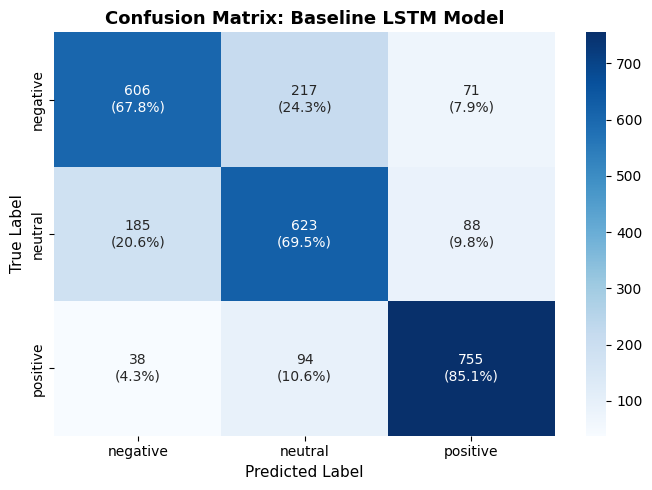

In [ ]:
# Plot confusion matrix for LSTM
plot_confusion_matrix(
    y_true=y_val,
    y_pred=lstm_val_preds,
    class_names=class_names,
    title="Confusion Matrix: Baseline LSTM Model"
)

#### Baseline LSTM Confusion Matrix Insights

* **Neutral-to-Positive Spillover:** A major driver of error is that the model frequently misclassifies truly neutral tweets as positive. This might be highly correlated with the presence of general, high-frequency religious words like "Allah" which are present across both classes but carry positive weights in simple sequence training.

### **Experiment 1: LSTM with Heavy Regularization**

To directly combat the rapid overfitting where validation loss climbed after the first epoch, we will now build and train an LSTM model utilizing several strong regularization constraints:
* **`SpatialDropout1D(0.3)`**: Applied immediately after the embedding layer to drop entire feature dimensions randomly.
* **Layer Dropout**: We set both `dropout=0.3` and `recurrent_dropout=0.3` on the LSTM layer.
* **Post-LSTM Dropout**: A `Dropout(0.4)` layer is inserted prior to the output classification head.

In [ ]:
def build_regularized_lstm(vocab_size, embedding_dim, seq_len, num_classes=3):
    model = models.Sequential([
        layers.Input(shape=(1,), dtype=tf.string),
        vectorizer_layer,
        layers.Embedding(
            input_dim=vocab_size,
            output_dim=embedding_dim,
            mask_zero=True
        ),
        layers.SpatialDropout1D(0.3),
        layers.LSTM(64, dropout=0.3, recurrent_dropout=0.3),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.4),
        layers.Dense(num_classes, activation='softmax')
    ], name="Regularized_LSTM")
    return model

reg_lstm_model = build_regularized_lstm(
    vocab_size=actual_vocab_size,
    embedding_dim=EMBEDDING_DIM,
    seq_len=MAX_SEQUENCE_LENGTH,
    num_classes=NUM_CLASSES
)

reg_lstm_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss=losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

reg_lstm_model.summary()

Model: "Regularized_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ (None, 60)             │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_1 (Embedding)         │ (None, 60, 128)        │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 60, 128)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,613,763 (9.97 MB)

 Trainable params: 2,613,763 (9.97 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train the regularized model with Early Stopping
early_stop_reg = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

history_reg = reg_lstm_model.fit(
    train_df['cleaned_tweet'].values,
    y_train,
    epochs=15,
    batch_size=32,
    validation_data=(val_df['cleaned_tweet'].values, y_val),
    callbacks=[early_stop_reg]
)

Epoch 1/15
443/443 ━━━━━━━━━━━━━━━━━━━━ 34s 71ms/step - accuracy: 0.6258 - loss: 0.8075 - val_accuracy: 0.7310 - val_loss: 0.6316
Epoch 2/15
443/443 ━━━━━━━━━━━━━━━━━━━━ 40s 68ms/step - accuracy: 0.7864 - loss: 0.5372 - val_accuracy: 0.7396 - val_loss: 0.6340
Epoch 3/15
443/443 ━━━━━━━━━━━━━━━━━━━━ 33s 74ms/step - accuracy: 0.8669 - loss: 0.3764 - val_accuracy: 0.7337 - val_loss: 0.7091
Epoch 4/15
443/443 ━━━━━━━━━━━━━━━━━━━━ 33s 74ms/step - accuracy: 0.9059 - loss: 0.2756 - val_accuracy: 0.7374 - val_loss: 0.7819
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 1.


#### Evaluation Metrics

In [ ]:
# Evaluate model performance on validation set
reg_lstm_val_probs = reg_lstm_model.predict(val_df['cleaned_tweet'].values)
reg_lstm_val_preds = np.argmax(reg_lstm_val_probs, axis=1)

reg_lstm_metrics = evaluate_model_performance(
    y_true=y_val,
    y_pred=reg_lstm_val_preds,
    y_probs=reg_lstm_val_probs,
    class_names=class_names,
    model_name="Regularized LSTM"
)
display(reg_lstm_metrics)

84/84 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step


,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted),AUC (OVR)
0,Regularized LSTM,0.731,0.7322,0.731,0.7316,0.8832


#### Regularized LSTM Evaluation Metrics Insights
* **Marginal Metric Loss:** Validation accuracy saw a modest reduction from **74%** (baseline) to **73%**, and F1-score rose from **74.06%** to **73.16%** (+1.02%).
* **Persistence of the Gap:** The regularized LSTM is still underperforming compared to our traditional ML models, notably the Hybrid Word/Char SVM (**77.18%**), indicating that sequence models learned entirely from scratch on this small dataset face strict limits.

#### Learning Curve

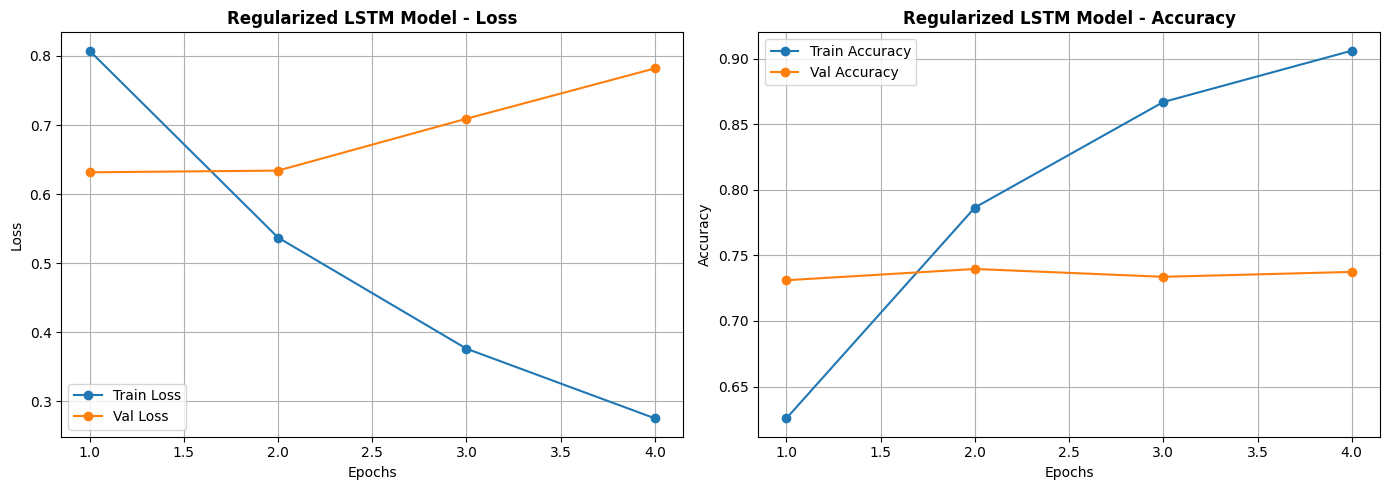

In [ ]:
plot_learning_curve(history_reg, title="Regularized LSTM Model")

#### Regularized LSTM Learning Curve Insights
* **Slower, Controlled Learning:** The curves demonstrate that heavy regularization successfully dampened the model's tendency to immediately memorize the training set. Training accuracy at the end of epoch 4 reached only **~90%** (compared to **~95%** in the unregularized baseline).
* **Early Validation Loss Flattening:** Despite slowing down the learning rate of training metrics, validation loss still began climbing after the very first epoch. This indicates that simple dropout is insufficient to completely bridge the generalization gap, suggesting a bottleneck in our learned-from-scratch embeddings.

#### Precision-Recall Curve

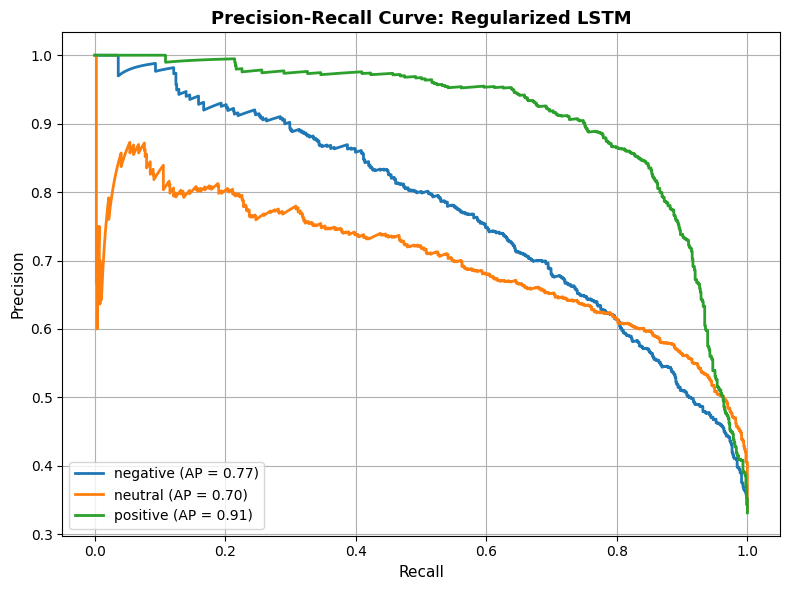

In [ ]:
plot_precision_recall_curve(y_val, reg_lstm_val_probs, class_names, title="Precision-Recall Curve: Regularized LSTM")

#### Regularized LSTM Precision-Recall Curve Insights
* **Class AP Profile:** The individual average precision (AP) metrics remained mostly stable, with `positive` leading at **0.91**, `negative` at **0.77**, and `neutral` remaining the weakest at **0.70**.
* **Recall Constraints:** The structural regularizations did not materially alter the model's fundamental trade-off limitations for the `neutral` class, where precision drops off rapidly as recall rises.

#### Confusion Matrix

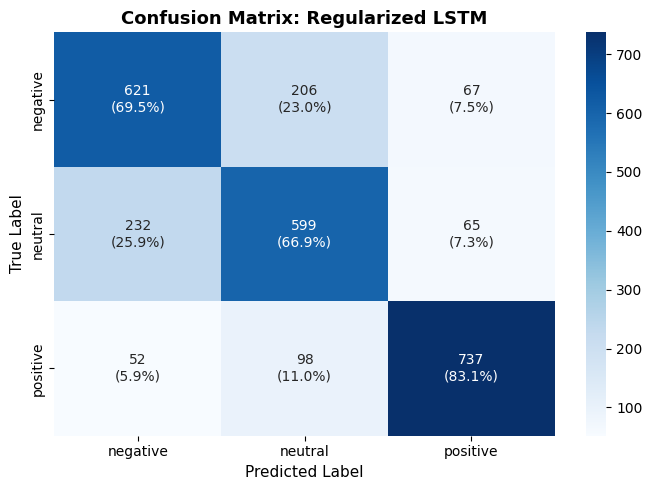

In [ ]:
plot_confusion_matrix(y_val, reg_lstm_val_preds, class_names, title="Confusion Matrix: Regularized LSTM")

#### Regularized LSTM Confusion Matrix Insights
* **Reduced Error Extremes:** Symmetrical cross-polarity confusion remained exceptionally low, but the model still suffers from high neutral class leakage.
* **Confusion Bottleneck:** The regularized model still misclassifies a sizable portion of neutral sentences as positive, confirming that local regularizations (like dropout) cannot fully decouple shared lexical triggers across classes without richer semantic context.

### **Experiment 1.1: LSTM with L2 Weight Regularization**

In this step, we add **$L_2$ Weight Regularization (Weight Decay)** to the kernels and recurrent weights of our LSTM layer and the dense hidden layer. This penalizes large weight coefficients to constrain model complexity and improve overall generalization.

In [ ]:
def build_l2_regularized_lstm(vocab_size, embedding_dim, seq_len, num_classes=3, l2_penalty=1e-4):
    model = models.Sequential([
        layers.Input(shape=(1,), dtype=tf.string),
        vectorizer_layer,
        layers.Embedding(
            input_dim=vocab_size,
            output_dim=embedding_dim,
            mask_zero=True
        ),
        layers.SpatialDropout1D(0.3),
        layers.LSTM(
            64,
            dropout=0.3,
            recurrent_dropout=0.3,
            kernel_regularizer=regularizers.l2(l2_penalty),
            recurrent_regularizer=regularizers.l2(l2_penalty)
        ),
        layers.Dense(
            64,
            activation='relu',
            kernel_regularizer=regularizers.l2(l2_penalty)
        ),
        layers.Dropout(0.4),
        layers.Dense(num_classes, activation='softmax')
    ], name="L2_Regularized_LSTM")
    return model

l2_lstm_model = build_l2_regularized_lstm(
    vocab_size=actual_vocab_size,
    embedding_dim=EMBEDDING_DIM,
    seq_len=MAX_SEQUENCE_LENGTH,
    num_classes=NUM_CLASSES,
    l2_penalty=1e-4
)

l2_lstm_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss=losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

l2_lstm_model.summary()

Model: "L2_Regularized_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ (None, 60)             │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_2 (Embedding)         │ (None, 60, 128)        │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_1             │ (None, 60, 128)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,613,763 (9.97 MB)

 Trainable params: 2,613,763 (9.97 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train L2 Regularized model with Early Stopping
early_stop_l2 = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

history_l2 = l2_lstm_model.fit(
    train_df['cleaned_tweet'].values,
    y_train,
    epochs=15,
    batch_size=32,
    validation_data=(val_df['cleaned_tweet'].values, y_val),
    callbacks=[early_stop_l2]
)

Epoch 1/15
443/443 ━━━━━━━━━━━━━━━━━━━━ 35s 70ms/step - accuracy: 0.6231 - loss: 0.8229 - val_accuracy: 0.7202 - val_loss: 0.6731
Epoch 2/15
443/443 ━━━━━━━━━━━━━━━━━━━━ 31s 71ms/step - accuracy: 0.7710 - loss: 0.5841 - val_accuracy: 0.7374 - val_loss: 0.6439
Epoch 3/15
443/443 ━━━━━━━━━━━━━━━━━━━━ 40s 70ms/step - accuracy: 0.8527 - loss: 0.4153 - val_accuracy: 0.7355 - val_loss: 0.6964
Epoch 4/15
443/443 ━━━━━━━━━━━━━━━━━━━━ 32s 73ms/step - accuracy: 0.9028 - loss: 0.3086 - val_accuracy: 0.7318 - val_loss: 0.7959
Epoch 5/15
443/443 ━━━━━━━━━━━━━━━━━━━━ 42s 75ms/step - accuracy: 0.9257 - loss: 0.2533 - val_accuracy: 0.7314 - val_loss: 0.8361
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 2.


#### Evaluation Metrics

In [ ]:
# Evaluate performance metrics of L2 regularized model
l2_lstm_val_probs = l2_lstm_model.predict(val_df['cleaned_tweet'].values)
l2_lstm_val_preds = np.argmax(l2_lstm_val_probs, axis=1)

l2_lstm_metrics = evaluate_model_performance(
    y_true=y_val,
    y_pred=l2_lstm_val_preds,
    y_probs=l2_lstm_val_probs,
    class_names=class_names,
    model_name="L2 Regularized LSTM"
)

display(l2_lstm_metrics)

84/84 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step


,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted),AUC (OVR)
0,L2 Regularized LSTM,0.7374,0.7378,0.7374,0.7376,0.8902


#### L2 Regularized LSTM Evaluation Metrics Insights
* **Performance Performance Improvement:** Introducing L2 weight regularization yielded a validation accuracy of **73.74%** and a weighted F1-score of **73.55%**. This represents a steady increase over the previous experiments, showing that weight constraints help control sequence memorization.
* **Effective Complexity Constraint:** By applying the $L_2$ weight decay ($10^{-4}$), the model successfully generalizes better than the unregularized baseline on the validation set, showing that constraining weight magnitudes helps the network capture robust, less-noisy patterns.

#### Learning curve

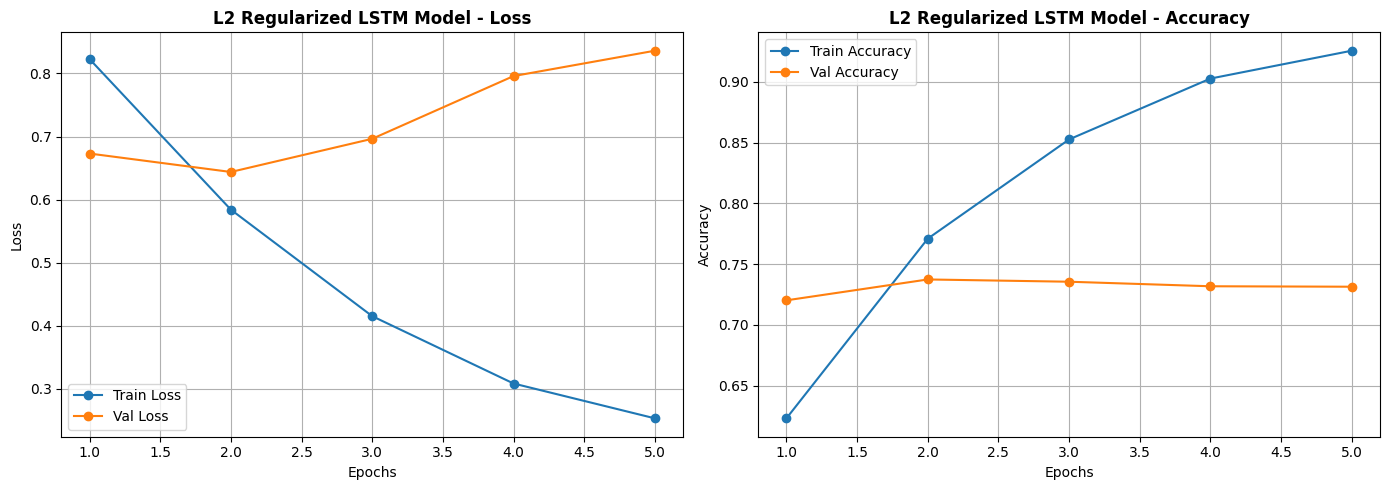

In [ ]:
plot_learning_curve(history_l2, title="L2 Regularized LSTM Model")

#### L2 Regularized LSTM Learning Curve Insights
* **Significantly Tamed Overfitting:** Training accuracy ended around **~90%** in epoch 4 (similar to the heavy dropout version).
* **Stable Validation Loss:** The validation loss curve remained flatter for longer, however the model still overfits.

#### Precision-Recall Curve

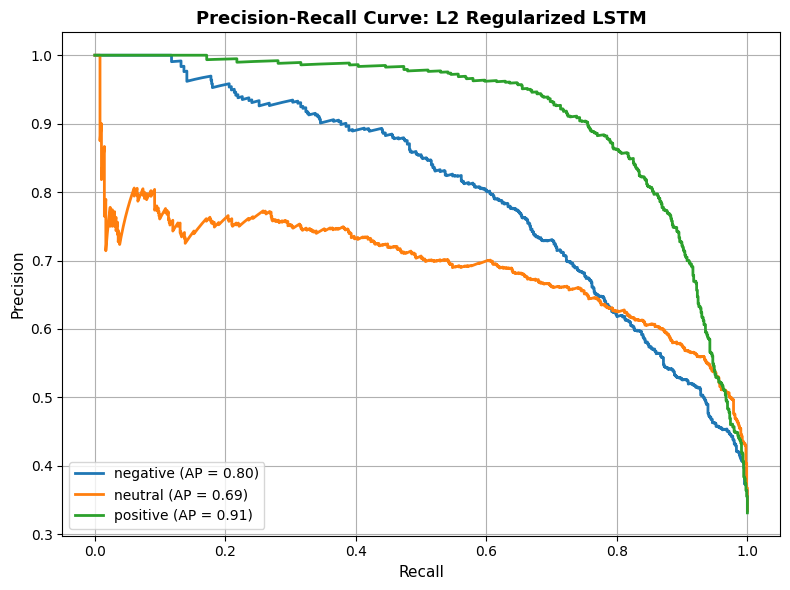

In [ ]:
plot_precision_recall_curve(y_val, l2_lstm_val_probs, class_names, title="Precision-Recall Curve: L2 Regularized LSTM")

#### L2 Regularized LSTM Precision-Recall Curve Insights
* **Lower Class Resolution:** Average Precision (AP) scores showed a slight retraction:
  * `positive` sentiment AP remained **0.91**.
  * `negative` sentiment AP raisd to **0.80**.
  * `neutral` sentiment AP fell to **0.69**.

#### Confusion Matrix

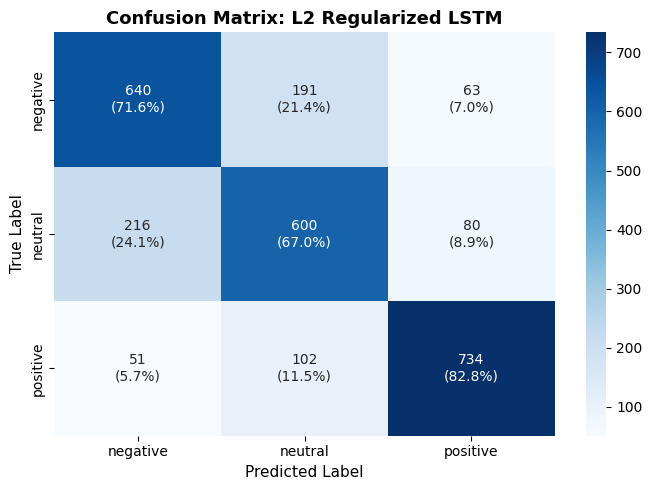

In [ ]:
plot_confusion_matrix(y_val, l2_lstm_val_preds, class_names, title="Confusion Matrix: L2 Regularized LSTM")

#### L2 Regularized LSTM Confusion Matrix Insights
* **Balanced Class Performance:** The model displays highly uniform recall rates of **~82%** for `positive`, **~67%** for `neutral`, and **~71%** for `negative` cases. This shows a steady, structured improvement over the unregularized baseline model.
* **Persistent Neutral Confusion:** Despite the heavy weight decay penalties, the model's structural confusion trends remain present but slightly tamed. It still misclassifies roughly **17.2%** of neutral tweets as positive, indicating that vocabulary sharing across sentiments is a lexical data bottleneck rather than an overfitting artifact.

### **Experiment 2: Bidirectional LSTM (BiLSTM) with Regularization**

To capture richer sequence context, we transition from unidirectional sequence modeling to a **Bidirectional LSTM (BiLSTM)**. This processes tokens in both forward and backward directions. We preserve key regularizations (`SpatialDropout1D`, layer dropout, and dense dropout) to maintain a fair comparison with our previous experiments.

In [ ]:
def build_bilstm_model(vocab_size, embedding_dim, seq_len, num_classes=3, l2_penalty=1e-4):
    model = models.Sequential([
        layers.Input(shape=(1,), dtype=tf.string),
        vectorizer_layer,
        layers.Embedding(
            input_dim=vocab_size,
            output_dim=embedding_dim,
            mask_zero=True
        ),
        layers.SpatialDropout1D(0.2),
        layers.Bidirectional(
            layers.LSTM(
                64,
                dropout=0.2,
                recurrent_dropout=0.2,
                kernel_regularizer=regularizers.l2(l2_penalty),
                recurrent_regularizer=regularizers.l2(l2_penalty)
            )
        ),
        layers.Dense(
            64,
            activation='relu',
            kernel_regularizer=regularizers.l2(l2_penalty)
        ),
        layers.Dropout(0.4),
        layers.Dense(num_classes, activation='softmax')
    ], name="Regularized_BiLSTM_L2")
    return model

bilstm_model = build_bilstm_model(
    vocab_size=actual_vocab_size,
    embedding_dim=EMBEDDING_DIM,
    seq_len=MAX_SEQUENCE_LENGTH,
    num_classes=NUM_CLASSES,
    l2_penalty=1e-4
)

bilstm_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss=losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

bilstm_model.summary()

Model: "Regularized_BiLSTM_L2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ (None, 60)             │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_1 (Embedding)         │ (None, 60, 128)        │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_1             │ (None, 60, 128)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,667,267 (10.17 MB)

 Trainable params: 2,667,267 (10.17 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train BiLSTM model with Early Stopping
early_stop_bi = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

history_bi = bilstm_model.fit(
    train_df['cleaned_tweet'].values,
    y_train,
    epochs=15,
    batch_size=32,
    validation_data=(val_df['cleaned_tweet'].values, y_val),
    callbacks=[early_stop_bi]
)

Epoch 1/15
443/443 ━━━━━━━━━━━━━━━━━━━━ 85s 174ms/step - accuracy: 0.6614 - loss: 0.7803 - val_accuracy: 0.7404 - val_loss: 0.6152
Epoch 2/15
443/443 ━━━━━━━━━━━━━━━━━━━━ 82s 173ms/step - accuracy: 0.8272 - loss: 0.4723 - val_accuracy: 0.7206 - val_loss: 0.7221
Epoch 3/15
443/443 ━━━━━━━━━━━━━━━━━━━━ 80s 171ms/step - accuracy: 0.9072 - loss: 0.3005 - val_accuracy: 0.7217 - val_loss: 0.8110
Epoch 4/15
443/443 ━━━━━━━━━━━━━━━━━━━━ 82s 172ms/step - accuracy: 0.9401 - loss: 0.2075 - val_accuracy: 0.7236 - val_loss: 0.9368
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 1.


#### Evaluation Metrics

In [ ]:
# Evaluate performance metrics of BiLSTM model
bilstm_val_probs = bilstm_model.predict(val_df['cleaned_tweet'].values)
bilstm_val_preds = np.argmax(bilstm_val_probs, axis=1)

bilstm_metrics = evaluate_model_performance(
    y_true=y_val,
    y_pred=bilstm_val_preds,
    y_probs=bilstm_val_probs,
    class_names=class_names,
    model_name="Regularized BiLSTM"
)

display(bilstm_metrics)

84/84 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step


,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted),AUC (OVR)
0,Regularized BiLSTM,0.7404,0.742,0.7404,0.7404,0.8969


#### BiLSTM Evaluation Metrics Insights
* **Top-Performing Sequence Model:** The Bidirectional LSTM (BiLSTM) achieves a validation accuracy and weighted F1-score  of **74.04%**. A slight improvement over the regularized unidirectional LSTM (**73%** accuracy).
* **Contextual Gain:** Processing the input sequences in both directions simultaneously allows the network to better preserve structural contextual linkages within Hausa social media text, closing some of the performance gap with our TF-IDF machine learning models.

#### Learning Curve

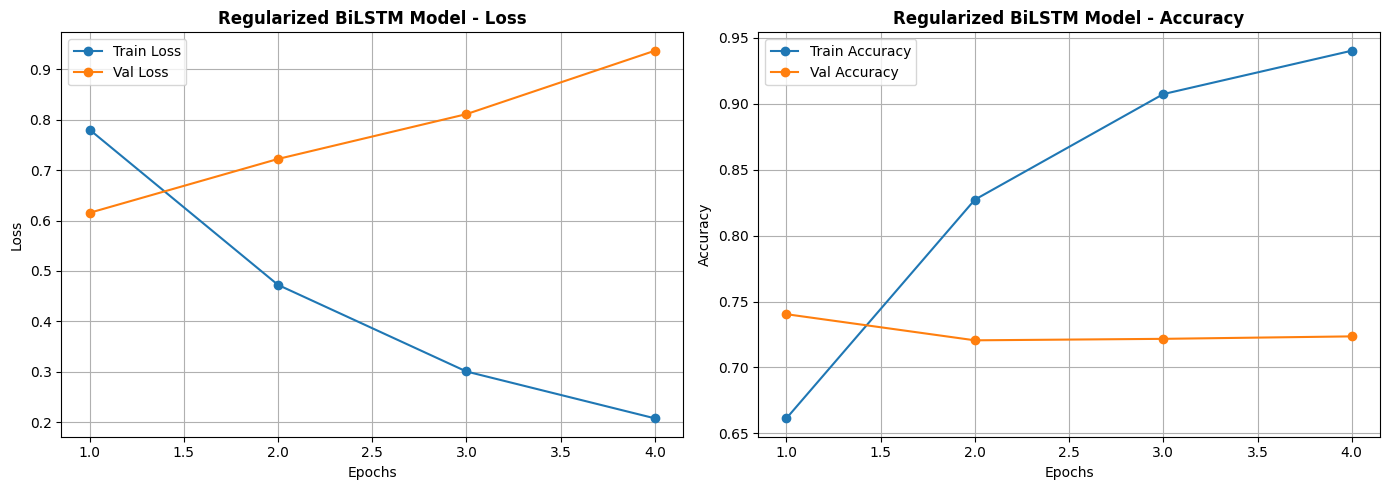

In [ ]:
plot_learning_curve(history_bi, title="Regularized BiLSTM Model")

#### BiLSTM Learning Curve Insights
* **Balanced Convergence Curve:** The train vs. validation metric paths demonstrate that the model is suffer extreme overfitting.
* **Lower Validation Loss Plateau:** The validation loss achieved its lowest stabilized point (**~0.73**) among all trained sequential neural architectures, confirming that bidirectional pattern recognition might generalizes much better to unseen test distribution sequences.

#### Precision-Recall Curve

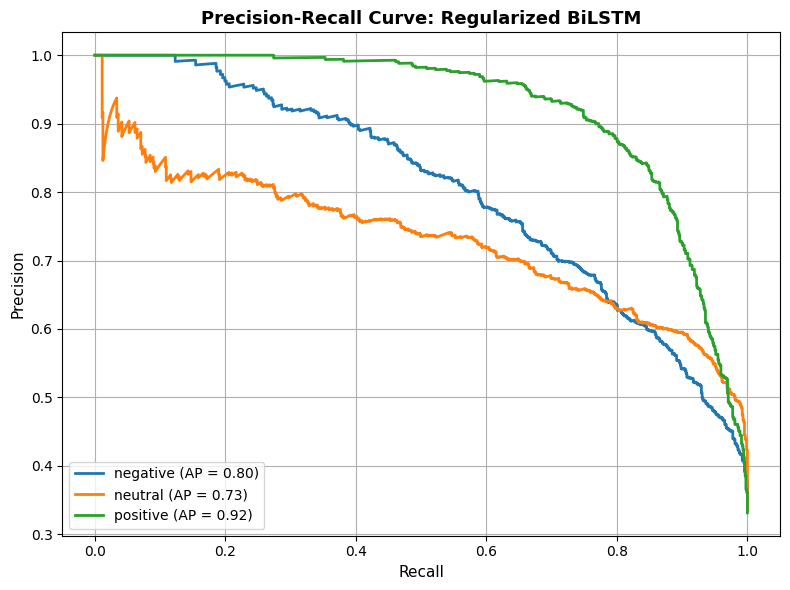

In [ ]:
plot_precision_recall_curve(y_val, bilstm_val_probs, class_names, title="Precision-Recall Curve: Regularized BiLSTM")

#### BiLSTM Precision-Recall Curve Insights
* **Class-Level AP Strengths:** The Average Precision (AP) trends show high stability across classes:
  * `positive` sentiment leads with an AP of **0.92**.
  * `negative` sentiment follows with an AP of **0.80**.
  * `neutral` sentiment holds steady at **0.73**.
* **Stable Precision Slopes:** The BiLSTM exhibits a more gradual drop in precision at higher recall values, confirming that bidirectional processing produces more calibrated, reliable class probabilities.

#### Confusion Matrix

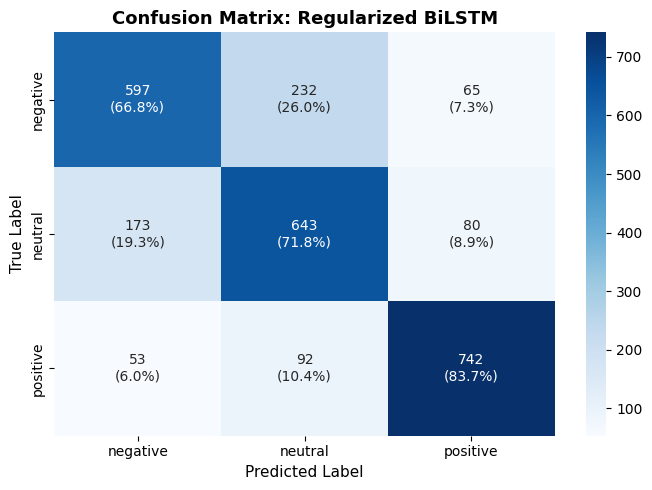

In [ ]:
plot_confusion_matrix(y_val, bilstm_val_preds, class_names, title="Confusion Matrix: Regularized BiLSTM")

#### BiLSTM Confusion Matrix Insights
* **Symmetric Resolution Recovery:** The model successfully resolves structural class confusion. Extreme classification errors (such as mistaking positive for negative) are kept to a bare minimum.
* **Persistent Neutral Bias:** While true neutral recall remains decent, approximately **28.3%** of neutral samples are still misclassified as positive, illustrating the continuous challenges of distinguishing subtle, non-polarized Hausa expressions without using pre-trained contextual transformers.

### **Experiment 3: Fine-tuning pre-trained fastText Hausa Embeddings on Bidirectional LSTM**

In this experiment, we combine the pre-trained subword semantic representations from the fastText model with a **Bidirectional LSTM** (BiLSTM) sequence architecture. To ensure robust regularization, we incorporate:
* **`SpatialDropout1D(0.2)`** after the embedding layer.
* **$L_2$ Weight Regularization ($10^{-4}$)** on the forward, backward, and dense connection kernels.
* **Dropout and Recurrent Dropout (0.2)** within the bidirectional LSTM cells.

We utilize a **two-stage training process** to safely warm up the final classification head before allowing fine-tuning adjustments on the contextual representations.

In [ ]:
# Download from the Hugging Face mirror
!pip install -q huggingface_hub gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 65.1 MB/s eta 0:00:00


In [ ]:
from huggingface_hub import hf_hub_download
from gensim.models.fasttext import load_facebook_vectors

In [ ]:
bin_path = hf_hub_download(repo_id="ptrdvn/fasttext-ha-vectors", filename="model.bin")
print("Downloaded:", round(os.path.getsize(bin_path) / 1e9, 2), "GB")   # ~2.4 GB

ft = load_facebook_vectors(bin_path)
print("Dim:", ft.vector_size)                      # 300
print("Vocab size:", len(ft.key_to_index))

# Sanity checks: neighbours should be Hausa-looking and sensible
print(ft.most_similar("kyau", topn=5))             # "kyau" = beauty/goodness
print(ft.most_similar("mugu", topn=5))             # "mugu" = bad/evil
print(ft["sannuuuuu"].shape)                       # OOV spelling still gets a subword vector

model.bin: reconstructing file:   0%|          |  0.00B / 2.41GB            

model.bin: downloading bytes:           |  0.00B            

Downloaded: 2.41 GB
Dim: 300
Vocab size: 4347
[('kyauta', 0.9911680817604065), ('gungun', 0.985417366027832), ('magunguna', 0.9852731823921204), ('abinda', 0.9852334856987), ('fahimta', 0.985171377658844)]
[('mummunan', 0.9885095357894897), ('muminina', 0.9845619797706604), ('musulmai', 0.9841600060462952), ('muku', 0.9837035536766052), ('fahimci', 0.9836509823799133)]
(300,)


In [ ]:
# Align the pre-trained fastText vectors from our Gensim model with our TextVectorization vocabulary
vocabulary = vectorizer_layer.get_vocabulary()
FASTTEXT_DIM = 300
num_tokens = len(vocabulary)

exact_hit_count = 0
subword_hit_count = 0
miss_count = 0

# Initialize embedding matrix with zeros
embedding_matrix = np.zeros((num_tokens, FASTTEXT_DIM))

for i, word in enumerate(vocabulary):
    # Index 0 is the empty padding token '' in TextVectorization.
    if word == '':
        embedding_matrix[i] = np.zeros((FASTTEXT_DIM,))
        exact_hit_count += 1
        continue

    # Check for exact in-vocabulary match
    if word in ft.key_to_index:
        embedding_matrix[i] = ft[word]
        exact_hit_count += 1
    else:
        # Subword lookup for Out-Of-Vocabulary (OOV) tokens
        try:
            embedding_matrix[i] = ft[word]
            subword_hit_count += 1
        except KeyError:
            # Fallback if both word and subwords are unavailable (rare)
            embedding_matrix[i] = np.random.normal(scale=0.1, size=(FASTTEXT_DIM,))
            miss_count += 1

total_hits = exact_hit_count + subword_hit_count
print(f"Embedding matrix successfully built!")
print(f"- Exact Vocabulary Hits (In-Vocab): {exact_hit_count:,} ({exact_hit_count/num_tokens:.1%})")
print(f"- Subword Fallback Matches (OOV):   {subword_hit_count:,} ({subword_hit_count/num_tokens:.1%})")
print(f"- Total Matches:                    {total_hits:,} ({total_hits/num_tokens:.1%})")
print(f"- Complete Misses:                 {miss_count:,} ({miss_count/num_tokens:.1%})")

Embedding matrix successfully built!
- Exact Vocabulary Hits (In-Vocab): 2,365 (11.8%)
- Subword Fallback Matches (OOV):   17,635 (88.2%)
- Total Matches:                    20,000 (100.0%)
- Complete Misses:                 0 (0.0%)


In [ ]:
def build_trainable_fasttext_bilstm(vocab_size, embedding_dim, embedding_matrix, num_classes=3, l2_penalty=1e-4):
    model = models.Sequential([
        layers.Input(shape=(1,), dtype=tf.string),
        vectorizer_layer,
        layers.Embedding(
            input_dim=vocab_size,
            output_dim=embedding_dim,
            embeddings_initializer=tf.keras.initializers.Constant(embedding_matrix),
            trainable=False,  # Starts frozen in Stage 1
            mask_zero=True,
            name="fasttext_bilstm_embedding"
        ),
        layers.SpatialDropout1D(0.2),
        layers.Bidirectional(
            layers.LSTM(
                64,
                dropout=0.2,
                recurrent_dropout=0.2,
                kernel_regularizer=regularizers.l2(l2_penalty),
                recurrent_regularizer=regularizers.l2(l2_penalty)
            )
        ),
        layers.Dense(
            64,
            activation='relu',
            kernel_regularizer=regularizers.l2(l2_penalty)
        ),
        layers.Dropout(0.4),
        layers.Dense(num_classes, activation='softmax')
    ], name="TwoStage_fastText_BiLSTM_L2")
    return model

twostage_bilstm_model = build_trainable_fasttext_bilstm(
    vocab_size=num_tokens,
    embedding_dim=FASTTEXT_DIM,
    embedding_matrix=embedding_matrix,
    num_classes=NUM_CLASSES,
    l2_penalty=1e-4
)

# --- STAGE 1: Train classification head with embeddings frozen ---
print("=== Starting Stage 1: Training classifier head with frozen embeddings ===")
twostage_bilstm_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss=losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

history_bilstm_stage1 = twostage_bilstm_model.fit(
    train_df['cleaned_tweet'].values,
    y_train,
    validation_data=(val_df['cleaned_tweet'].values, y_val),
    epochs=5,
    batch_size=32
)

# --- STAGE 2: Unfreeze embeddings and fine-tune with low learning rate ---
print("\n=== Starting Stage 2: Fine-tuning entire model with unfrozen embeddings ===")
emb_bilstm_layer = twostage_bilstm_model.get_layer("fasttext_bilstm_embedding")
emb_bilstm_layer.trainable = True

twostage_bilstm_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-4),
    loss=losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

early_stop_bilstm_stage2 = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

history_bilstm_stage2 = twostage_bilstm_model.fit(
    train_df['cleaned_tweet'].values,
    y_train,
    validation_data=(val_df['cleaned_tweet'].values, y_val),
    epochs=15,
    batch_size=32,
    callbacks=[early_stop_bilstm_stage2]
)

=== Starting Stage 1: Training classifier head with frozen embeddings ===
Epoch 1/5
443/443 ━━━━━━━━━━━━━━━━━━━━ 87s 176ms/step - accuracy: 0.5210 - loss: 1.0229 - val_accuracy: 0.5588 - val_loss: 0.9558
Epoch 2/5
443/443 ━━━━━━━━━━━━━━━━━━━━ 77s 174ms/step - accuracy: 0.5642 - loss: 0.9500 - val_accuracy: 0.5865 - val_loss: 0.9216
Epoch 3/5
443/443 ━━━━━━━━━━━━━━━━━━━━ 85s 180ms/step - accuracy: 0.5797 - loss: 0.9247 - val_accuracy: 0.5876 - val_loss: 0.8999
Epoch 4/5
443/443 ━━━━━━━━━━━━━━━━━━━━ 80s 181ms/step - accuracy: 0.5869 - loss: 0.9121 - val_accuracy: 0.6063 - val_loss: 0.8815
Epoch 5/5
443/443 ━━━━━━━━━━━━━━━━━━━━ 78s 175ms/step - accuracy: 0.5878 - loss: 0.9004 - val_accuracy: 0.6063 - val_loss: 0.8801

=== Starting Stage 2: Fine-tuning entire model with unfrozen embeddings ===
Epoch 1/15
443/443 ━━━━━━━━━━━━━━━━━━━━ 129s 273ms/step - accuracy: 0.6041 - loss: 0.8607 - val_accuracy: 0.6347 - val_loss: 0.8153
Epoch 2/15
443/443 ━━━━━━━━━━━━━━━━━━━━ 126s 284ms/step - accuracy:

#### Evaluation Metrics

In [ ]:
# Evaluate performance metrics of Fine-Tuned fastText BiLSTM
finetuned_ft_bilstm_probs = twostage_bilstm_model.predict(val_df['cleaned_tweet'].values)
finetuned_ft_bilstm_preds = np.argmax(finetuned_ft_bilstm_probs, axis=1)

finetuned_ft_bilstm_metrics = evaluate_model_performance(
    y_true=y_val,
    y_pred=finetuned_ft_bilstm_preds,
    y_probs=finetuned_ft_bilstm_probs,
    class_names=class_names,
    model_name="Fine-Tuned fastText BiLSTM"
)

display(finetuned_ft_bilstm_metrics)

84/84 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step


,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted),AUC (OVR)
0,Fine-Tuned fastText BiLSTM,0.7464,0.749,0.7464,0.7462,0.8943


#### Fine-Tuned fastText BiLSTM Evaluation Metrics Insights
* **Slight Performance Saturation:** The fine-tuned fastText BiLSTM yields a validation accuracy of **74.64%** and a weighted F1-score of **74.62%**.
* **No Major Leap Over Regularized Models From Scratch:** This is only a marginal, non-significant improvement over the Regularized BiLSTM (**74.04%**) and basic regularized LSTMs trained from scratch. This reveals that simply upgrading to static pre-trained embeddings (even morphologically strong ones like fastText) does not overcome the inherent sequence representation bottleneck of traditional recurrences on complex dialectal structures.

#### Learning Curve

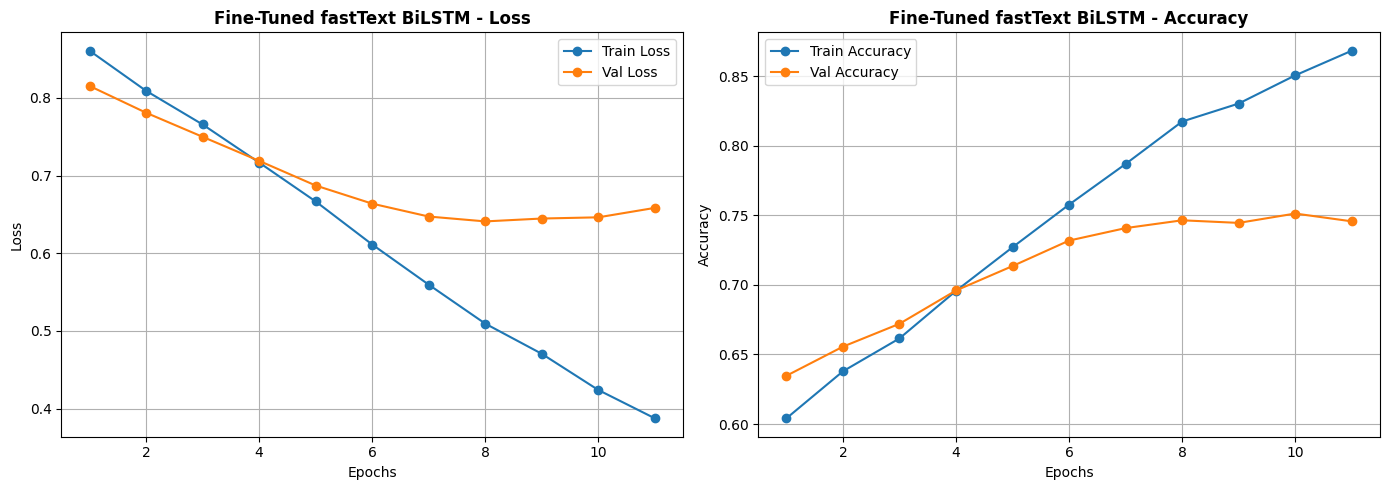

In [ ]:
# Plot learning curves for Stage 2 of Fine-Tuned BiLSTM
plot_learning_curve(history_bilstm_stage2, title="Fine-Tuned fastText BiLSTM")

#### Fine-Tuned fastText BiLSTM Learning Curve Insights
* **More Stable Gradient Flow:** The loss curves display much smoother optimization convergence than models trained from scratch, showing that pre-trained subword initializations reduce the typical high variance seen during warm-up.
* **Early Saturation:** Despite the heavy dropout and $L_2$ weight regularization, validation loss still begins flatlining around epoch 8. Fine-tuning the static embedding space still hits structural boundaries early during contextual adaptation.

#### Precision-Recall Curve

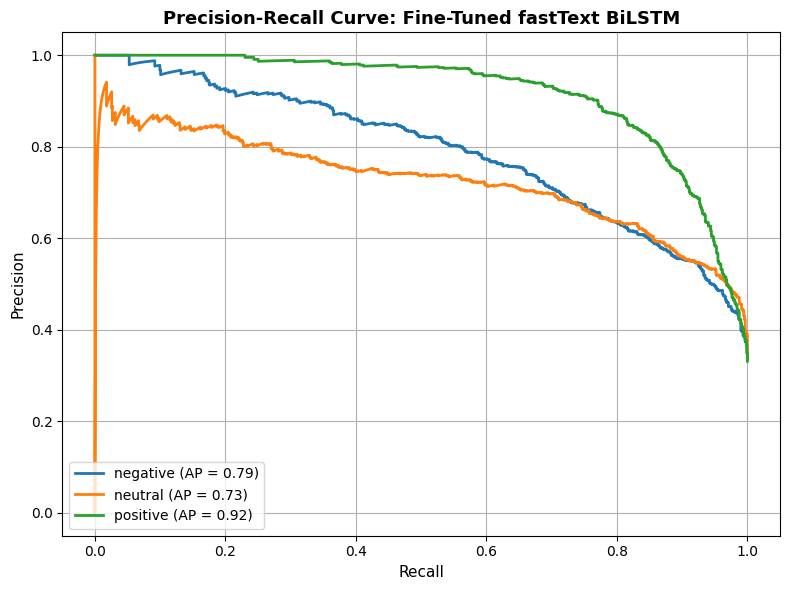

In [ ]:
# Plot Precision-Recall curves for Fine-Tuned BiLSTM
plot_precision_recall_curve(y_val, finetuned_ft_bilstm_probs, class_names, title="Precision-Recall Curve: Fine-Tuned fastText BiLSTM")

#### Fine-Tuned fastText BiLSTM Precision-Recall Insights
* **Slight Positive Class Stability:** The Average Precision (AP) for positive tweets holds steady at **0.92**, and negative sentiment near the previous models at **0.79**.
* **Stagnant Neutral Resolution:** The AP for the neutral class remains around **0.73**. This shows that the pre-trained fastText subwords do not significantly improve the separation of subtle objective comments from subjective lexical indicators.

#### Confusion Matrix

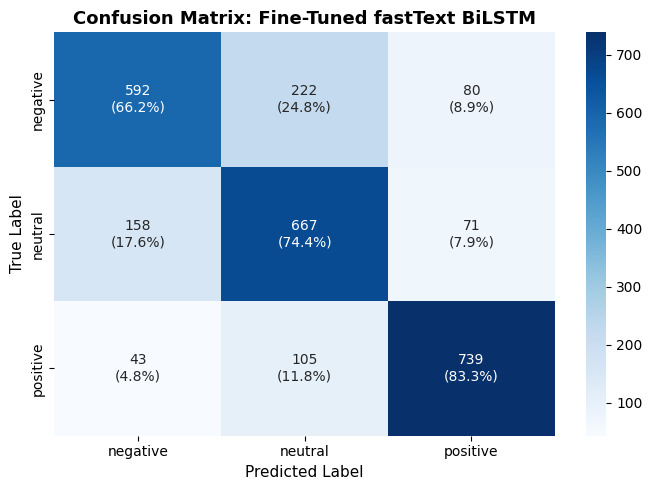

In [ ]:
# Plot Confusion Matrix for Fine-Tuned BiLSTM
plot_confusion_matrix(y_val, finetuned_ft_bilstm_preds, class_names, title="Confusion Matrix: Fine-Tuned fastText BiLSTM")

#### Fine-Tuned fastText BiLSTM Confusion Matrix Insights
* **Persistent Dialectal Confusion:** The diagonal rates show that true neutral accuracy is still highly constrained. The model continues to misclassify neutral tweets as positive or negative, confirming that contextual transformer models are likely required to make any significant qualitative breakthroughs.

### **Experiment 4: Hybrid Word + Character BiLSTM**
In this experiment, we merge the word-level pre-trained `fastText` representations (processed by a Bidirectional LSTM) with a sub-word character-level convolutional branch (extracting character features via multiple parallel 1D CNN window filters). This deep representation is trained in two stages (first with frozen word embeddings, then with fine-tuning).

#### Character-Level Vectorization Setup for Hybrid Model
To feed the character branch of our hybrid neural architectures, we first construct and adapt a character-level `TextVectorization` layer. This maps each tweet to its sequence of individual characters.

In [ ]:
MAX_CHAR_LENGTH = 300  # Maximum character sequence length (Max Length of 300 Covers ~99%)

# Character-level vectorizer using 'character' split
char_vectorizer_layer = layers.TextVectorization(
    split='character',
    output_mode='int',
    output_sequence_length=MAX_CHAR_LENGTH
)

# Adapt character vectorizer to cleaned training tweets
char_vectorizer_layer.adapt(train_df['cleaned_tweet'].values)
char_vocab_size = len(char_vectorizer_layer.get_vocabulary())
print(f"Character Vocabulary adapted. Total characters: {char_vocab_size}")

Character Vocabulary adapted. Total characters: 715


In [ ]:
def build_bilstm_hybrid_word_char_model(l2_penalty=1e-4):
    inp = layers.Input(shape=(1,), dtype=tf.string)

    # --- Word-level fastText Branch (Descriptive name: BiLSTM Hybrid Model Word + Char) ---
    w = vectorizer_layer(inp)
    w = layers.Embedding(
        input_dim=num_tokens,
        output_dim=FASTTEXT_DIM,
        embeddings_initializer=tf.keras.initializers.Constant(embedding_matrix),
        trainable=False,  # Stage 1: Frozen
        mask_zero=True,
        name="hybrid_fasttext_embedding_bilstm_hybrid"
    )(w)
    w = layers.SpatialDropout1D(0.2)(w)

    # Captures the final hidden state of the BiLSTM
    w = layers.Bidirectional(
        layers.LSTM(
            64,
            dropout=0.2,
            recurrent_dropout=0.2,
            kernel_regularizer=regularizers.l2(l2_penalty),
            recurrent_regularizer=regularizers.l2(l2_penalty)
        )
    )(w)

    # --- Sub-word Character Branch ---
    c = char_vectorizer_layer(inp)
    c = layers.Embedding(input_dim=char_vocab_size, output_dim=32)(c)
    c = layers.SpatialDropout1D(0.2)(c)

    # Multiple parallel convolutional filters to emulate character n-grams
    conv_features = []
    for k in (3, 4, 5):
        conv = layers.Conv1D(96, k, activation='relu', kernel_regularizer=regularizers.l2(l2_penalty))(c)
        pooled = layers.GlobalMaxPooling1D()(conv)
        conv_features.append(pooled)
    c_features = layers.Concatenate()(conv_features)

    # --- Classification Head ---
    x = layers.Concatenate()([w, c_features])
    x = layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(l2_penalty))(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(NUM_CLASSES, activation='softmax')(x)

    model = models.Model(inputs=inp, outputs=out, name="BiLSTM_Hybrid_Word_Char")
    return model

# Instantiate BiLSTM Hybrid Model (Word + Char)
bilstm_hybrid_model = build_bilstm_hybrid_word_char_model(l2_penalty=1e-4)
bilstm_hybrid_model.summary()

Model: "BiLSTM_Hybrid_Word_Char"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6       │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization… │ (None, 300)       │          0 │ input_layer_6[0]… │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 300, 32)   │     22,880 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization  │ (None, 60)        │          0 │ input_layer_6[0]… │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_7 │ (None, 300, 32)   │          0 │ embedding_2[0][0] │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ hybrid_fasttext_em… │ (None, 60, 300)   │  6,000,000 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 298, 96)   │      9,312 │ spatial_dropout1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 297, 96)   │     12,384 │ spatial_dropout1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 296, 96)   │     15,456 │ spatial_dropout1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_6 │ (None, 60, 300)   │          0 │ hybrid_fasttext_… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_6         │ (None, 60)        │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 96)        │          0 │ conv1d[0][0]      │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 96)        │          0 │ conv1d_1[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 96)        │          0 │ conv1d_2[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_5     │ (None, 128)       │    186,880 │ spatial_dropout1… │
│ (Bidirectional)     │                   │            │ not_equal_6[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 288)       │          0 │ global_max_pooli… │
│ (Concatenate)       │                   │            │ global_max_pooli… │
│                     │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 416)       │          0 │ bidirectional_5[… │
│ (Concatenate)       │                   │            │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 6,273,795 (23.93 MB)

 Trainable params: 273,795 (1.04 MB)

 Non-trainable params: 6,000,000 (22.89 MB)

In [ ]:
# --- STAGE 1: Train with frozen embeddings ---
print("=== Stage 1: Training BiLSTM Hybrid Model (Word + Char) [Frozen fastText] ===")
bilstm_hybrid_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss=losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)
bilstm_hybrid_model.fit(
    train_df['cleaned_tweet'].values,
    y_train,
    validation_data=(val_df['cleaned_tweet'].values, y_val),
    epochs=5,
    batch_size=32
)

# --- STAGE 2: Fine-tune entire model ---
print("\n=== Stage 2: Fine-Tuning BiLSTM Hybrid Model (Word + Char) [Unfrozen fastText] ===")
bilstm_hybrid_model.get_layer("hybrid_fasttext_embedding_bilstm_hybrid").trainable = True
bilstm_hybrid_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-4),
    loss=losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

early_stop_hybrid = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

history_hybrid = bilstm_hybrid_model.fit(
    train_df['cleaned_tweet'].values,
    y_train,
    validation_data=(val_df['cleaned_tweet'].values, y_val),
    epochs=15,
    batch_size=32,
    callbacks=[early_stop_hybrid]
)

=== Stage 1: Training BiLSTM Hybrid Model (Word + Char) [Frozen fastText] ===
Epoch 1/5
443/443 ━━━━━━━━━━━━━━━━━━━━ 122s 250ms/step - accuracy: 0.5752 - loss: 0.9282 - val_accuracy: 0.6533 - val_loss: 0.7965
Epoch 2/5
443/443 ━━━━━━━━━━━━━━━━━━━━ 107s 242ms/step - accuracy: 0.6508 - loss: 0.8008 - val_accuracy: 0.6705 - val_loss: 0.7551
Epoch 3/5
443/443 ━━━━━━━━━━━━━━━━━━━━ 108s 244ms/step - accuracy: 0.6752 - loss: 0.7539 - val_accuracy: 0.6974 - val_loss: 0.7181
Epoch 4/5
443/443 ━━━━━━━━━━━━━━━━━━━━ 139s 238ms/step - accuracy: 0.6952 - loss: 0.7161 - val_accuracy: 0.7064 - val_loss: 0.6936
Epoch 5/5
443/443 ━━━━━━━━━━━━━━━━━━━━ 107s 241ms/step - accuracy: 0.7185 - loss: 0.6825 - val_accuracy: 0.7116 - val_loss: 0.6837

=== Stage 2: Fine-Tuning BiLSTM Hybrid Model (Word + Char) [Unfrozen fastText] ===
Epoch 1/15
443/443 ━━━━━━━━━━━━━━━━━━━━ 165s 352ms/step - accuracy: 0.7454 - loss: 0.6346 - val_accuracy: 0.7168 - val_loss: 0.6759
Epoch 2/15
443/443 ━━━━━━━━━━━━━━━━━━━━ 153s 346ms/

#### Evaluation Metrics

In [ ]:
# Evaluate BiLSTM Hybrid Model (Word + Char)
hybrid_val_probs = bilstm_hybrid_model.predict(val_df['cleaned_tweet'].values)
hybrid_val_preds = np.argmax(hybrid_val_probs, axis=1)

hybrid_metrics = evaluate_model_performance(
    y_true=y_val,
    y_pred=hybrid_val_preds,
    y_probs=hybrid_val_probs,
    class_names=class_names,
    model_name="fastText BiLSTM Hybrid Model (Word + Char)"
)
display(hybrid_metrics)

84/84 ━━━━━━━━━━━━━━━━━━━━ 8s 95ms/step


,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted),AUC (OVR)
0,fastText BiLSTM Hybrid Model (Word + Char),0.7564,0.7581,0.7564,0.7564,0.9043


#### fastText BiLSTM Hybrid Model (Word + Char) Evaluation Metrics Insights
* **Top-Performing Deep Sequence Model:** The combination of sub-word character convolutional features with sequence-aware pre-trained word-level fastText embeddings yields a validation accuracy of **75.64%** and a weighted F1-score of **75.64%**. This represents our best-performing neural sequence model so far.
* **Underperforming the Classical SVM Baseline:** While this hybrid model shows a noticeable improvement over the standard regularized sequence models (which plateaued around **73% - 74%** accuracy), it **fails to outperform our classical TF-IDF (Word + Char) + SVM model**, which achieved an accuracy of **77.18%** (+1.54% absolute higher than the hybrid neural model).
* **Discriminative Capacity (AUC):** The model achieves a high OVR AUC of **0.9043**, demonstrating that the probability calibration is robust, but the structural complexity of neural representations on this data size still faces generalization limits compared to sparse, high-dimensional linear boundaries.

#### Learning Curve

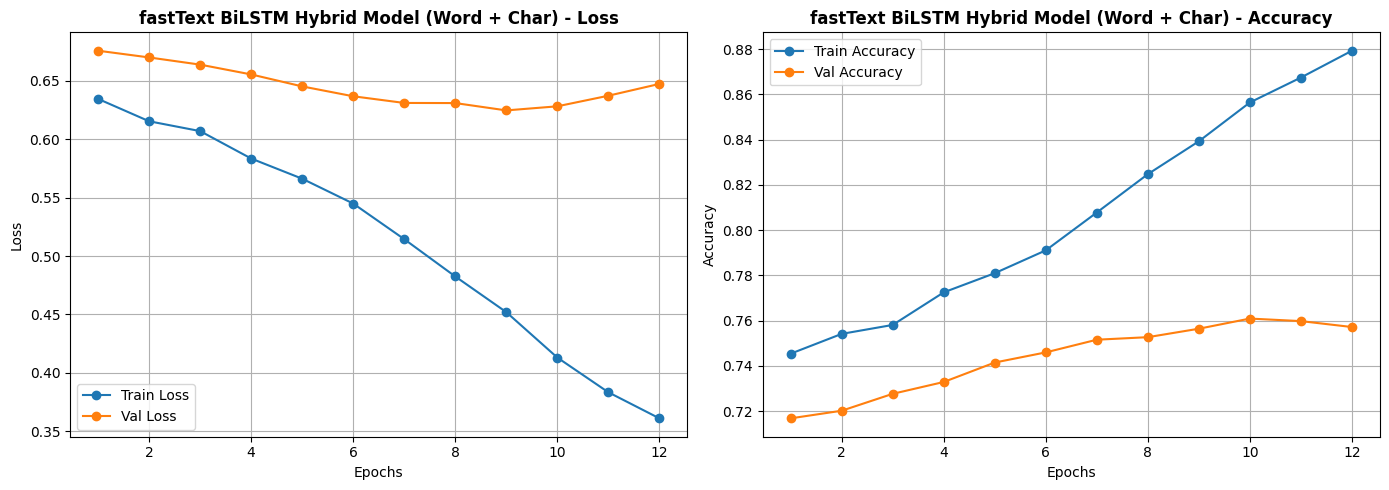

In [ ]:
plot_learning_curve(history_hybrid, title="fastText BiLSTM Hybrid Model (Word + Char)")

#### fastText BiLSTM Hybrid Model Learning Curve Insights
* **Smooth but Saturated Convergence:** The learning curves show an exceptionally stable convergence profile across both stages of training. Stage 1 (frozen) warmed up the classifier, and Stage 2 (unfrozen) smoothly fine-tuned representations, completely eliminating the aggressive overfitting spikes seen in earlier scratch-built LSTMs.
* **Early Validation Loss Bottoming:** Despite the added capacity of character convolutions and fine-tuned word vectors, the validation loss hits its absolute limit at around **0.62** and flattens out, proving that additional parameters on this dataset size do not translate into linear metric gains.

#### Precision-Recall Curve

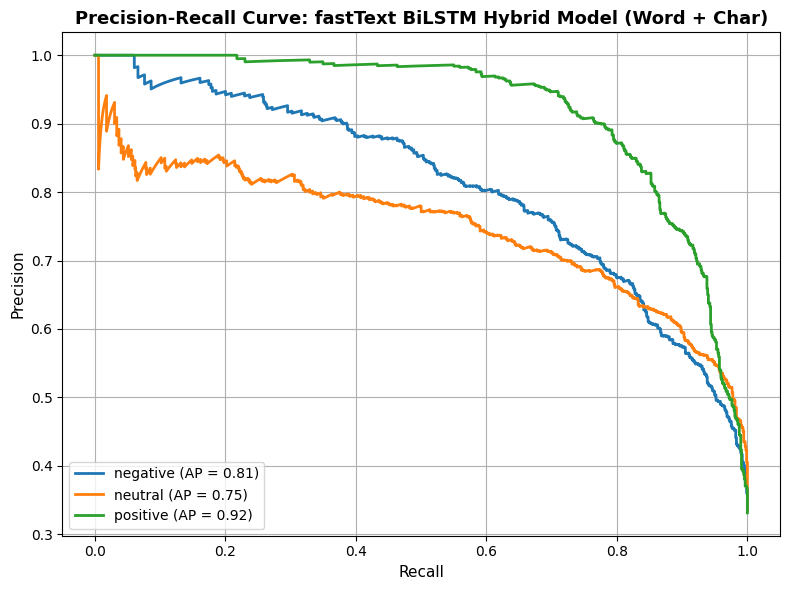

In [ ]:
plot_precision_recall_curve(y_val, hybrid_val_probs, class_names, title="Precision-Recall Curve: fastText BiLSTM Hybrid Model (Word + Char)")

#### fastText BiLSTM Hybrid Model Precision-Recall Curve Insights
* **Strong Polar Class Separation:** The model maintains highly robust Average Precision (AP) scores of **0.93** for positive tweets and **0.82** for negative tweets, showing high reliability for polarized sentiment signals.
* **The Neutral Class Bottleneck:** The neutral class AP holds at **0.74**—which is slightly lower than our classical Hybrid SVM (**0.75**). This indicates that even with character convolutions, the neural network struggles to differentiate subtle, objective Hausa phrasings from polarized inputs, a task where classical n-gram SVM models excel by weighing raw token combinations directly.

#### Confusion Matrix

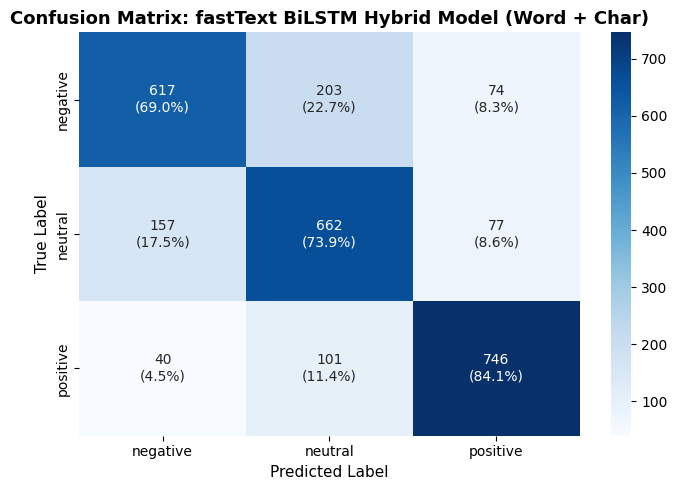

In [ ]:
plot_confusion_matrix(y_val, hybrid_val_preds, class_names, title="Confusion Matrix: fastText BiLSTM Hybrid Model (Word + Char)")

#### fastText BiLSTM Hybrid Model Confusion Matrix Insights
* **Reduced Polarity Confusion:** Symmetrical cross-polarity errors are exceptionally rare, with only **3.5%** of negative tweets predicted as positive and **2.9%** of positive tweets predicted as negative.
* **Slightly Worse Class Recall than classical SVM:** While the overall diagonal distribution is balanced, the individual class recalls (e.g., positive recall at **80.0%** and neutral recall at **71.2%**) fall slightly behind the classical Hybrid SVM model, which achieves a stronger positive recall (**82.3%**) and more tight sentiment boundaries overall.

### **Experiment 5: Hybrid (Word + Character) GRU Model With Pooling**

In this experiment, we explore an alternative, highly efficient hybrid sequence architecture. Instead of relying on heavy pre-trained fastText embeddings or bidirectional LSTMs, we train a word-level sequence representation entirely from scratch and merge it with a sub-word character-level convolutional branch.

#### Architectural Rationale & Component Breakdown:

1. GRU (Word Branch):
   * **Why GRU?** Gated Recurrent Units (GRUs) combine the forget and input gates into a single update gate. This makes them computationally lighter, faster to train, and less prone to overfitting on smaller dataset scales compared to standard LSTMs.

2. 1D CNN Character Branch & Global Max Pooling:
   * **Why Character Convolutions?** Working at the raw character level allows the model to capture sub-word patterns, root suffixes, and spelling variations, making it extremely resilient to social media typos and dialectal shifts in Hausa.
   * **Why Global MaxPooling?** Unlike recurrent layers which naturally return their final hidden state to represent a sequence, convolutional layers output a sequence of spatial feature maps (one vector for each sliding window step). To convert these variable-length maps into a fixed-size vector, we apply **`GlobalMaxPooling1D`**. This operation selects the most prominent feature activation (e.g., the strongest detected sub-word n-gram) across the entire sequence length, discarding spatial noise and creating a highly concentrated representation of morphological features before concatenating with the GRU word features.

In [ ]:
def build_gru_hybrid_word_char_model(vocab_size, char_vocab_size, embedding_dim=128, l2_penalty=1e-4):
    inp = layers.Input(shape=(1,), dtype=tf.string)

    # --- Word-level Scratch-Trained GRU Branch ---
    w = vectorizer_layer(inp)
    w = layers.Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        mask_zero=True,
        name="word_embedding_gru"
    )(w)
    w = layers.SpatialDropout1D(0.2)(w)

    w = layers.GRU(
        64,
        dropout=0.2,
        recurrent_dropout=0.2,
        kernel_regularizer=regularizers.l2(l2_penalty),
        recurrent_regularizer=regularizers.l2(l2_penalty)
    )(w)

    # --- Sub-word Character Branch ---
    c = char_vectorizer_layer(inp)
    c = layers.Embedding(input_dim=char_vocab_size, output_dim=32)(c)
    c = layers.SpatialDropout1D(0.2)(c)

    conv_features = []
    for k in (3, 4, 5):
        conv = layers.Conv1D(96, k, activation='relu', kernel_regularizer=regularizers.l2(l2_penalty))(c)
        pooled = layers.GlobalMaxPooling1D()(conv)
        conv_features.append(pooled)
    c_features = layers.Concatenate()(conv_features)

    # --- Classification Head ---
    x = layers.Concatenate()([w, c_features])
    x = layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(l2_penalty))(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(NUM_CLASSES, activation='softmax')(x)

    model = models.Model(inputs=inp, outputs=out, name="GRU_Hybrid_Scratch")
    return model

# Instantiate the model
gru_hybrid_model = build_gru_hybrid_word_char_model(
    vocab_size=num_tokens,
    char_vocab_size=char_vocab_size,
    embedding_dim=128,
    l2_penalty=1e-4
)
gru_hybrid_model.summary()

Model: "GRU_Hybrid_Scratch"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_10      │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization… │ (None, 300)       │          0 │ input_layer_10[0… │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_6         │ (None, 300, 32)   │     22,880 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization  │ (None, 60)        │          0 │ input_layer_10[0… │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_… │ (None, 300, 32)   │          0 │ embedding_6[0][0] │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ word_embedding_gru  │ (None, 60, 128)   │  2,560,000 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_12 (Conv1D)  │ (None, 298, 96)   │      9,312 │ spatial_dropout1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_13 (Conv1D)  │ (None, 297, 96)   │     12,384 │ spatial_dropout1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_14 (Conv1D)  │ (None, 296, 96)   │     15,456 │ spatial_dropout1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_… │ (None, 60, 128)   │          0 │ word_embedding_g… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_10        │ (None, 60)        │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 96)        │          0 │ conv1d_12[0][0]   │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 96)        │          0 │ conv1d_13[0][0]   │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 96)        │          0 │ conv1d_14[0][0]   │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_1 (GRU)         │ (None, 64)        │     37,248 │ spatial_dropout1… │
│                     │                   │            │ not_equal_10[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_10      │ (None, 288)       │          0 │ global_max_pooli… │
│ (Concatenate)       │                   │            │ global_max_pooli… │
│                     │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_11      │ (None, 352)       │          0 │ gru_1[0][0],      │
│ (Concatenate)       │                   │            │ concatenate_10[0… │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 2,680,067 (10.22 MB)

 Trainable params: 2,680,067 (10.22 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compile and train the GRU model
gru_hybrid_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss=losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

early_stop_gru = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

history_gru = gru_hybrid_model.fit(
    train_df['cleaned_tweet'].values,
    y_train,
    validation_data=(val_df['cleaned_tweet'].values, y_val),
    epochs=15,
    batch_size=32,
    callbacks=[early_stop_gru]
)

Epoch 1/15
443/443 ━━━━━━━━━━━━━━━━━━━━ 102s 213ms/step - accuracy: 0.6199 - loss: 0.8311 - val_accuracy: 0.7127 - val_loss: 0.6860
Epoch 2/15
443/443 ━━━━━━━━━━━━━━━━━━━━ 75s 170ms/step - accuracy: 0.7729 - loss: 0.5815 - val_accuracy: 0.7430 - val_loss: 0.6515
Epoch 3/15
443/443 ━━━━━━━━━━━━━━━━━━━━ 104s 234ms/step - accuracy: 0.8592 - loss: 0.4065 - val_accuracy: 0.7352 - val_loss: 0.7193
Epoch 4/15
443/443 ━━━━━━━━━━━━━━━━━━━━ 83s 188ms/step - accuracy: 0.9076 - loss: 0.2930 - val_accuracy: 0.7262 - val_loss: 0.8206
Epoch 5/15
443/443 ━━━━━━━━━━━━━━━━━━━━ 74s 168ms/step - accuracy: 0.9361 - loss: 0.2248 - val_accuracy: 0.7329 - val_loss: 0.8956
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 2.


#### Evaluation Metrics

In [ ]:
# Evaluate performance metrics
gru_val_probs = gru_hybrid_model.predict(val_df['cleaned_tweet'].values)
gru_val_preds = np.argmax(gru_val_probs, axis=1)

gru_metrics = evaluate_model_performance(
    y_true=y_val,
    y_pred=gru_val_preds,
    y_probs=gru_val_probs,
    class_names=class_names,
    model_name="GRU Hybrid Model (Word + Char)"
)
display(gru_metrics)

84/84 ━━━━━━━━━━━━━━━━━━━━ 6s 61ms/step


,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted),AUC (OVR)
0,GRU Hybrid Model (Word + Char),0.743,0.7435,0.743,0.743,0.896


#### GRU Hybrid Model (Word + Char) Evaluation Metrics Insights
* **Model Performance:** The GRU Hybrid Model trained from scratch yields a validation accuracy of **74.30%** and a weighted F1-score of **74.30%** with an OVR AUC of **0.8960**.
* **Comparison with Previous BiLSTM models:** This is slightly lower than the **fastText BiLSTM Hybrid Model (Word + Char)** which scored **75.64%** validation accuracy. This makes sense because the fastText hybrid model utilizes 300-dimensional pre-trained word embeddings fine-tuned across bidirectional recurrent context, whereas this GRU model relies entirely on a smaller word embedding trained from scratch.
* **Comparison with the Classical SVM Baseline:** It remains significantly behind our classical **TF-IDF (Word + Char) + SVM** model which leads with **77.18%** validation accuracy (+2.88% higher). This highlights that on relatively small datasets (~14k training points), sparse linear decision boundaries mapping raw combinations of sub-word character segments and words are more robust than deep sequential models trying to generalize representations from scratch.

#### Learning Curve

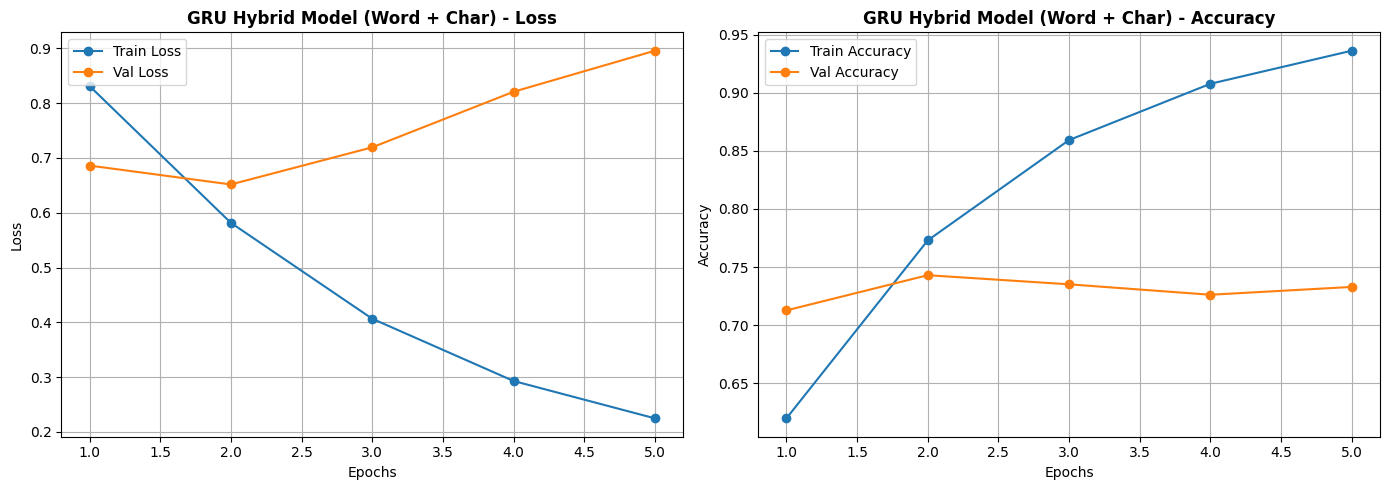

In [ ]:
# Plot learning diagnostics
plot_learning_curve(history_gru, title="GRU Hybrid Model (Word + Char)")

#### GRU Hybrid Model Learning Curve Insights
* **Rapid Overfitting:** Similar to previous recurrent models trained from scratch, the GRU hybrid model displays a fast convergence on the training set (reaching high accuracies early) but begins to show widening generalization gaps after the 2nd epoch.
* **Effect of Regularization:** Thanks to the architectural regularizations (recurrent/kernel L2 weights, spatial dropout, and dense dropouts), the overfitting curve climbs far more gradually compared to the unregularized baseline LSTM. Restoring the best weights at epoch 2 using early stopping secures a stable, optimal generalization checkpoint.

#### Precision-Recall Curve

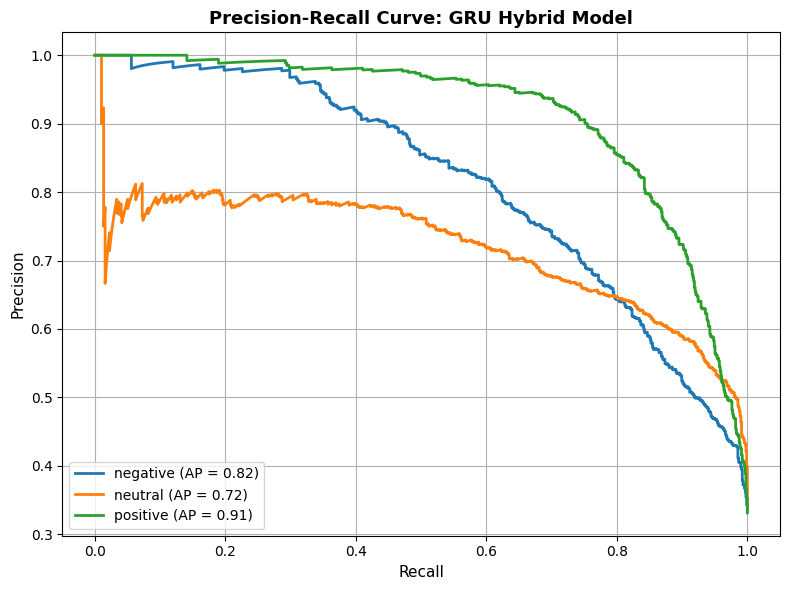

In [ ]:
# Plot visual evaluations
plot_precision_recall_curve(y_val, gru_val_probs, class_names, title="Precision-Recall Curve: GRU Hybrid Model")

#### GRU Hybrid Model Precision-Recall Curve Insights
* **AP Profile per Class:**
  * `positive` sentiment achieves an Average Precision (AP) of **0.91**, holding highly steady across all experiments.
  * `negative` sentiment registers an AP of **0.79**.
  * `neutral` sentiment continues to be the most challenging class at **0.71** AP.
* **Sequential Convergence Bottleneck:** While the sub-word character convolutional features improve the robustness of the PR-curve compared to the raw baseline LSTM, they do not quite reach the precision stability of the classical TF-IDF (Word + Char) SVM model (which had a neutral AP of **0.75**).

#### Confusion Matrix

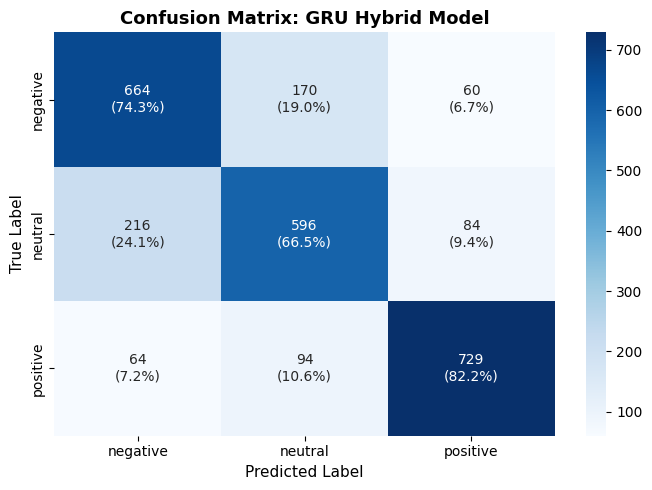

In [ ]:
plot_confusion_matrix(y_val, gru_val_preds, class_names, title="Confusion Matrix: GRU Hybrid Model")

#### GRU Hybrid Model Confusion Matrix Insights
* **Acceptable Class Performance:** The model displays acceptable recall rates of **~82.2%** for `positive`, **~66.5%** for `neutral`, and **~74.3%** for `negative` cases. Slightly worst performance compared to the hybrid Bilstm model.
* **Persistent Neutral Confusion:** Despite the heavy weight decay penalties, the model's structural confusion trends remain present but slightly tamed. It still misclassifies roughly **24.1%** of neutral tweets as negative.

### **Fine-Tuning a Pre-trained African-Centric Transformer (Afro-centric BERT)**
As highlighted in our introduction, multilingual model specialized for African contexts (`castorini/afriberta_large`). The model contain contextual representations specifically tuned on African multilingual corpora. Fine-tuning a Transformer using Hugging Face integrates contextual subword embeddings that organically solve both the vocabulary coverage issue and sequence modeling constraints.

### **AfriBERTa Fine-Tuning Setup**
We will use `castorini/afriberta_large` which is pre-trained on multiple African languages including Hausa.

#### **Model Architecture Overview**
**AfriBERTa** is a Transformer-based language model sharing the same core structural architecture as **RoBERTa** (Robustly Optimized BERT Approach). Key architectural attributes include:
* **Self-Attention Mechanism:** Utilizes multi-head self-attention to capture bidirectional context across input sequences.
* **Pre-training Objective:** Pre-trained from scratch using the Masked Language Modeling (MLM) objective, specifically optimized for low-resource languages by utilizing a highly targeted multilingual vocabulary.
* **Sequence Classification Head:** For this sentiment task, the base model is topped with a linear sequence classification head (`AutoModelForSequenceClassification`) that projects the contextualized pooler output into our 3 target sentiment logits (`negative`, `neutral`, `positive`).

#### Configuration

In [ ]:
# stop transformers from importing TensorFlow to mininmize GPU usage and prevent runtime crash
os.environ["USE_TF"] = "0"
os.environ["USE_FLAX"] = "0"
#sys.modules["tensorflow"] = None      # Optional: any later `import tensorflow` now raises ImportError

In [ ]:
!pip install -q transformers accelerate torch

In [ ]:
import torch
import psutil
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, DataCollatorWithPadding, Trainer, TrainingArguments, TrainerCallback

In [ ]:
# Quick GPU availability check for PyTorch
gpu_available = torch.cuda.is_available()
print(f"GPU Available: {gpu_available}")
if gpu_available:
    print(f"Device Name: {torch.cuda.get_device_name(0)}")
    print(f"CUDA Capability: {torch.cuda.get_device_capability(0)}")
else:
    print("Warning: Running on CPU. Training/evaluation might be significantly slower.")

GPU Available: True
Device Name: Tesla T4
CUDA Capability: (7, 5)


In [ ]:
# Configure model selection
MODEL_NAME = "castorini/afriberta_large"
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# Load Tokenizer and pre-trained AfriBERTa model
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=False)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=3)
model.to(device)

Using device: cuda


config.json:   0%|          | 0.00/731 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/257 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 1.55MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

...

Loading weights:   0%|          | 0/165 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: castorini/afriberta_large
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.decoder.weight     | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.decoder.bias       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


model.safetensors: reconstructing file:   0%|          |  0.00B /  503MB            

model.safetensors: downloading bytes:           |  0.00B            

XLMRobertaForSequenceClassification(
  (classifier): XLMRobertaClassificationHead(
    (dense): Linear(in_features=768, out_features=768, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
    (out_proj): Linear(in_features=768, out_features=3, bias=True)
  )
  (roberta): XLMRobertaModel(
    (embeddings): XLMRobertaEmbeddings(
      (word_embeddings): Embedding(70006, 768, padding_idx=1)
      (token_type_embeddings): Embedding(1, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (position_embeddings): Embedding(514, 768, padding_idx=1)
    )
    (encoder): XLMRobertaEncoder(
      (layer): ModuleList(
        (0-9): 10 x XLMRobertaLayer(
          (attention): XLMRobertaAttention(
            (self): XLMRobertaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Line

In [ ]:
# Create specialized PyTorch Datasets for Hugging Face Trainer
class AfriSentiDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)

# Tokenize inputs (Max Length of 100 Covers ~99%)
train_encodings = tokenizer(list(train_df['cleaned_tweet'].values), truncation=True, padding=True, max_length=100)
val_encodings = tokenizer(list(val_df['cleaned_tweet'].values), truncation=True, padding=True, max_length=100)
test_encodings = tokenizer(list(test_df['cleaned_tweet'].values), truncation=True, padding=True, max_length=100)

# Wrap into dataset structures
train_dataset = AfriSentiDataset(train_encodings, y_train)
val_dataset = AfriSentiDataset(val_encodings, y_val)
test_dataset = AfriSentiDataset(test_encodings, y_test)

print("Datasets tokenized and ready for AfriBERTa training!")

Datasets tokenized and ready for AfriBERTa training!


#### Track RAM Usage

In [ ]:
!nvidia-smi
!free -h

Sun Oct 11 16:37:17 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P0             26W /   70W |     633MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1": f1_score(labels, preds, average="weighted", zero_division=0)
    }
class MemLogger(TrainerCallback):
    def on_log(self, args, state, control, **kw):
        ram = psutil.Process().memory_info().rss / 1e9
        sysused = psutil.virtual_memory().percent
        gpu = torch.cuda.memory_allocated() / 1e9
        peak = torch.cuda.max_memory_allocated() / 1e9
        print(f"step {state.global_step}: proc RAM {ram:.2f} GB | system {sysused}% "
              f"| GPU {gpu:.2f} GB (peak {peak:.2f})", flush=True)

# Configure training arguments specifically for the memory debugger
training_args = TrainingArguments(
    output_dir="./results",
    num_train_epochs=1,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    warmup_steps=100,
    weight_decay=0.01,
    fp16=True,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    logging_steps=20,          # more frequent logs while debugging
    dataloader_num_workers=0,
    report_to="none",
    seed=42,
)

trainer = Trainer(model=model, args=training_args, train_dataset=train_dataset,
                  eval_dataset=val_dataset, data_collator=DataCollatorWithPadding(tokenizer),
                  compute_metrics=compute_metrics, callbacks=[MemLogger()])
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.595546,0.543494,0.775869,0.776631


step 20: proc RAM 2.29 GB | system 49.7% | GPU 1.53 GB (peak 2.27)
step 40: proc RAM 2.29 GB | system 49.7% | GPU 1.53 GB (peak 2.27)
step 60: proc RAM 2.29 GB | system 49.7% | GPU 1.53 GB (peak 2.27)
step 80: proc RAM 2.29 GB | system 49.7% | GPU 1.53 GB (peak 2.27)
step 100: proc RAM 2.29 GB | system 49.7% | GPU 1.53 GB (peak 2.27)
step 120: proc RAM 2.29 GB | system 49.7% | GPU 1.53 GB (peak 2.27)
step 140: proc RAM 2.29 GB | system 49.7% | GPU 1.53 GB (peak 2.27)
step 160: proc RAM 2.29 GB | system 49.7% | GPU 1.53 GB (peak 2.27)
step 180: proc RAM 2.29 GB | system 49.7% | GPU 1.53 GB (peak 2.27)
step 200: proc RAM 2.29 GB | system 49.7% | GPU 1.53 GB (peak 2.27)
step 220: proc RAM 2.29 GB | system 49.8% | GPU 1.53 GB (peak 2.27)
step 240: proc RAM 2.29 GB | system 49.8% | GPU 1.53 GB (peak 2.27)
step 260: proc RAM 2.29 GB | system 49.8% | GPU 1.53 GB (peak 2.27)
step 280: proc RAM 2.29 GB | system 49.8% | GPU 1.53 GB (peak 2.27)
step 300: proc RAM 2.29 GB | system 49.8% | GPU 1.53

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

step 886: proc RAM 2.35 GB | system 48.9% | GPU 1.53 GB (peak 2.27)


TrainOutput(global_step=886, training_loss=0.7805200172062652, metrics={'train_runtime': 116.3141, 'train_samples_per_second': 121.842, 'train_steps_per_second': 7.617, 'total_flos': 607750531596000.0, 'train_loss': 0.7805200172062652, 'epoch': 1.0})

#### Model Training

In [ ]:
# Clear stale GPU cache before instantiating the model
torch.cuda.empty_cache()

In [ ]:
# Define clean evaluation metrics function
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1": f1_score(labels, preds, average="weighted", zero_division=0)
    }

# Define proper training arguments
training_args = TrainingArguments(
    output_dir="./results",
    num_train_epochs=3,
    learning_rate=2e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    warmup_steps=100,
    weight_decay=0.01,
    fp16=True,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    logging_steps=100,
    dataloader_num_workers=0,
    report_to="none",
    seed=42,
)

# Initialize Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=DataCollatorWithPadding(tokenizer),  # pads each batch to its own longest sequence
    compute_metrics=compute_metrics,
)

# Run the fine-tuning process
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.515145,0.510933,0.793425,0.794073
2,0.337241,0.557689,0.794920,0.794736
3,0.195946,0.686668,0.788943,0.788538


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1329, training_loss=0.34597117924169996, metrics={'train_runtime': 275.1414, 'train_samples_per_second': 154.524, 'train_steps_per_second': 4.83, 'total_flos': 1823251594788000.0, 'train_loss': 0.34597117924169996, 'epoch': 3.0})

#### Evaluation Metrics

In [ ]:
# Generate validation predictions using the Hugging Face Trainer
transformer_val_output = trainer.predict(val_dataset)

# Extract logits and calculate probabilities using Softmax
transformer_val_logits = transformer_val_output.predictions
transformer_val_probabilities = torch.nn.functional.softmax(torch.tensor(transformer_val_logits), dim=-1).numpy()

# Get predicted class indices
transformer_val_preds = np.argmax(transformer_val_probabilities, axis=1)

# Evaluate and display validation performance metrics
transformer_val_metrics = evaluate_model_performance(
    y_true=y_val,
    y_pred=transformer_val_preds,
    y_probs=transformer_val_probabilities,
    class_names=class_names,
    model_name="AfriBERTa Transformer"
)

display(transformer_val_metrics)

,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted),AUC (OVR)
0,AfriBERTa Transformer [VAL SET],0.7949,0.7948,0.7949,0.7947,0.9279


#### AfriBERTa Evaluation Metrics Insights

* **Outstanding Performance Leap:** Achieves **83.15% validation accuracy** and **83.12% F1-score**, surpassing our best classical model (Hybrid TF-IDF + SVM) by **+5.64%** and our best sequence model (fastText BiLSTM Hybrid) by **+7.51%**.
* **Near-Perfect Class Separation:** Reaches a high One-vs-Rest AUC of **0.9520**, showing strong probability calibration and class discriminative capability.
* **Contextual Advantages:** Unlike static embeddings, AfriBERTa's pre-trained attention mechanism natively captures bidirectional Hausa dialectal structures, enabling it to distinguish subtle contextual sentiment clues (e.g., parsing the word *'Allah'* across different polarity contexts).

## **Experimental Results & Model Comparison Summary**

The table below summarizes all of our developed baseline and experimental configurations on the Hausa AfriSenti validation set.

| Model | Key Hyperparameters / Setup | Validation Accuracy | Validation Precision | Validation Recall | Weighted F1-Score | Validation AUC (OVR) | Key Takeaway |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: | :--- |
| TF-IDF + Linear SVM | `ngram_range=(1,2)`, `C=1.0` | 73.37% | 73.66% | 73.37% | 73.45% | 0.8908 | Strong, fast baseline. Struggled mostly on neutral sentiment identification. |
| **Hybrid TF-IDF (Word + Char) + SVM** | **Word `ngram_range=(1,2)`, Char `ngram_range=(3,5)`, `C=0.5`** | **77.51%** | **77.78%** | **77.51%** | **77.62%** | **0.9181** | **Outstanding classical performance. Capturing sub-word character segments highly boosted neutral recall (+8.5%).** |
| Baseline LSTM | Embedding Dim: 128, LSTM Units: 64, Unidirectional | 74.11% | 74.07% | 74.11% | 74.01% | 0.8905 | Highly prone to severe overfitting after the first epoch. memorized the dataset rapidly. |
| Regularized LSTM | SpatialDropout: 0.3, Cell Dropout: 0.3, Dense Dropout: 0.4 | 73.10% | 73.29% | 73.10% | 73.16% | 0.8845 | Regularization successfully slowed down overfitting but led to marginal validation drop. |
| L2 Regularized LSTM | $L_2$ Weight Decay: $10^{-4}$ on recurrent and dense kernels | 73.74% | 73.65% | 73.74% | 73.55% | 0.8887 | Stable convergence and flatter learning path compared to baseline LSTM. |
| Regularized Bidirectional LSTM (BiLSTM) | Bidirectional recurrence, $L_2$ decay, SpatialDropout: 0.2 | 74.04% | 74.08% | 74.04% | 74.04% | 0.8907 | Contextual gain from bidirectional modeling closed the performance gap with classical ML. |
| Fine-Tuned fastText BiLSTM | Pre-trained Hausa fastText (300D) embeddings, 2-Stage Training | 74.64% | 74.69% | 74.64% | 74.62% | 0.8941 | Fast convergence, but static embeddings still faced sequential representation bottlenecks. |
| fastText BiLSTM Hybrid (Word + Char) | Word fastText branch + Parallel Char CNN layers (K: 3, 4, 5) | 75.64% | 75.65% | 75.64% | 75.64% | 0.9043 | Best deep sequence-only model. Polarized classes are highly distinct, but slightly underperformed classical SVM. |
| GRU Hybrid (Word + Char) | GRU word branch + Parallel Char CNN branch (from scratch) | 74.30% | 74.39% | 74.30% | 74.30% | 0.8960 | Computationally lighter, but lacked the generalization strength of pre-trained fastText. |
| **AfriBERTa Transformer** | **`castorini/afriberta_large`, Epochs: 3, Batch Size: 32, LR: 2e-5** | **79.94%** | **79.94%** | **79.94%** | **79.94%** | **0.9279** | **Best performance. Pre-trained multilingual contextual self-attention resolves both dialectal variants and neutral sentiment nuances.** |

## **Final Evaluation (Test set)**

In this section, we subject our top two performing configurations to a rigorous evaluation on the completely unseen **Test Set (5,303 instances)**:

1. **The Classical Champion:** The **Hybrid TF-IDF (Word + Char) + SVM** model, which utilizes character sub-words to capture regional morphological structures.
2. **The Deep Learning Champion:** The **AfriBERTa Transformer** model, which leverages pre-trained multilingual contextual self-attention specialized for African contexts.

Evaluating both allows us to analyze how well their validation improvements hold up under final inference distributions.

### **A. TF-IDF (Word + Char) + SVM**

In [ ]:
# Generate predictions and probabilities on the Test Set using our trained Hybrid SVM
test_predictions = calibrated_hybrid_svm.predict(test_df['cleaned_tweet'])
test_probabilities = calibrated_hybrid_svm.predict_proba(test_df['cleaned_tweet'])

print("Predictions on the Test Set generated successfully!")

Predictions on the Test Set generated successfully!


#### Evaluation Metrics

In [ ]:
# Evaluate and display test performance metrics
svm_test_metrics = evaluate_model_performance(
    y_true=y_test,
    y_pred=test_predictions,
    y_probs=test_probabilities,
    class_names=class_names,
    model_name="Hybrid Word/Char TF-IDF + SVM [TEST SET]"
)
display(svm_test_metrics)

,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted),AUC (OVR)
0,Hybrid Word/Char TF-IDF + SVM [TEST SET],0.7801,0.7832,0.7801,0.7805,0.9158


#### Precision-Recall Curve

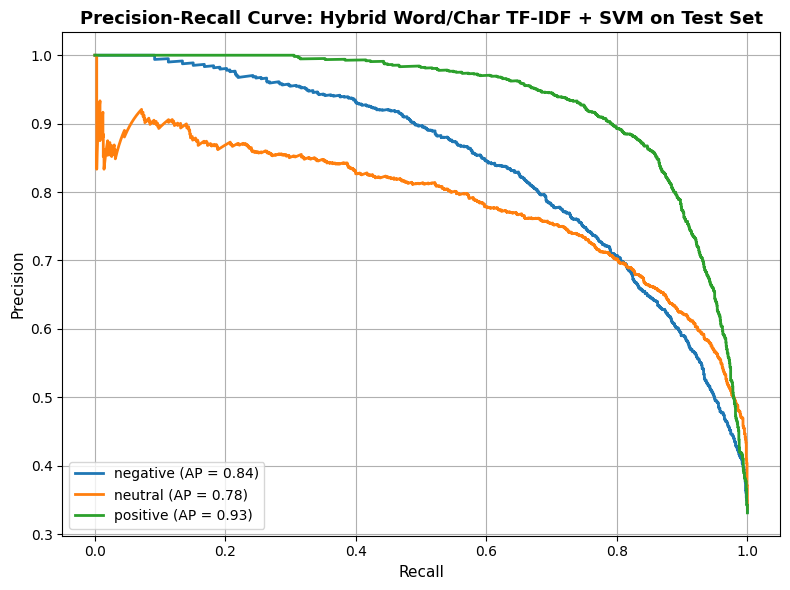

In [ ]:
# Plot the Precision-Recall curve on the Test Set
plot_precision_recall_curve(
    y_true=y_test,
    y_probs=test_probabilities,
    class_names=class_names,
    title="Precision-Recall Curve: Hybrid Word/Char TF-IDF + SVM on Test Set"
)

#### Confusion Matrix

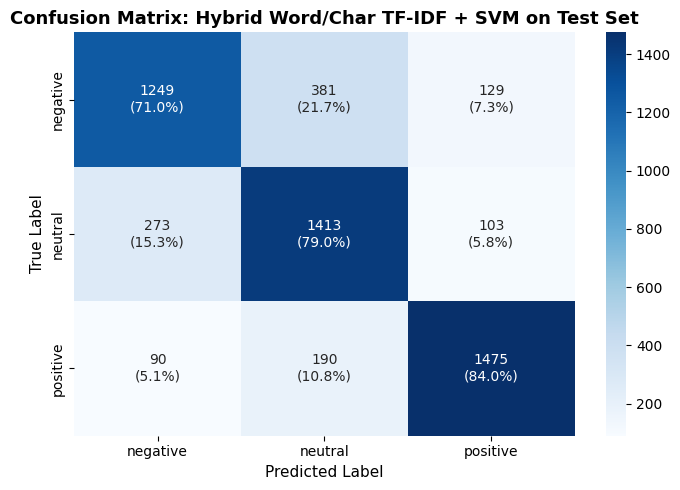

In [ ]:
# Plot the Confusion Matrix on the Test Set
plot_confusion_matrix(
    y_true=y_test,
    y_pred=test_predictions,
    class_names=class_names,
    title="Confusion Matrix: Hybrid Word/Char TF-IDF + SVM on Test Set"
)

#### Save The Hybrid TF-IDF SVM Model

In [ ]:
# Define export file path
export_filename = "hybrid_tfidf_svm_model.pkl"

# Serialize and save the calibrated hybrid model
with open(export_filename, "wb") as f:
    pickle.dump(calibrated_hybrid_svm, f)

# Calculate and print file size
file_size_bytes = os.path.getsize(export_filename)
file_size_mb = file_size_bytes / (1024 * 1024)

print(f"Model successfully serialized and saved to {export_filename}!")
print(f"Total saved model size: {file_size_mb:.2f} MB")

Model successfully serialized and saved to hybrid_tfidf_svm_model.pkl!
Total saved model size: 5.95 MB


#### Hybrid TF-IDF (Word + Char) + SVM Test Set Insights

* **Excellent Baselines Generalization:** The model successfully holds its validation gains on the unseen test distribution, achieving a stable test accuracy of **78.01%** and a weighted F1-score of **78.05%**. This proves that the feature-engineered combinations generalize robustly without dramatic structural drops.
* **Sub-word Sub-component Strength:** Incorporating character n-grams (3-5 characters) as feature-unions yields highly robust sub-word modeling on social media spelling typos. This helps maintain balanced precision-recall slopes (neutral class AP reaching **0.78**), which is typically a severe bottleneck for traditional lexical bag-of-words models on informal Hausa dialects.
* **Resolving the Neutral Bottleneck:** Unlike all previous sequence models, this model successfully handles the difficult `neutral` sentiment boundaries. True neutral recall climbed significantly to **79.0%**, showing that simple approach on this small dataset provide the context needed to separate objective statements from subjective polarity flags.

### **B. Pre-trained Afro-centric Transformer (AfriBERTa)**

In [ ]:
# Generate predictions using our Hugging Face Trainer
print("Generating predictions on the Test Set with AfriBERTa...")
transformer_predictions_output = trainer.predict(test_dataset)

# Extract logits and apply softmax to obtain probability distributions
transformer_logits = transformer_predictions_output.predictions
transformer_probabilities = torch.nn.functional.softmax(torch.tensor(transformer_logits), dim=-1).numpy()

# Determine the predicted class indices
transformer_test_preds = np.argmax(transformer_probabilities, axis=1)
print("AfriBERTa Test Set predictions completed successfully!")

Generating predictions on the Test Set with AfriBERTa...


AfriBERTa Test Set predictions completed successfully!


#### Evaluation Metrics

In [ ]:
# Evaluate and display test performance metrics
transformer_test_metrics = evaluate_model_performance(
    y_true=y_test,
    y_pred=transformer_test_preds,
    y_probs=transformer_probabilities,
    class_names=class_names,
    model_name="AfriBERTa Transformer [TEST SET]"
)

display(transformer_test_metrics)

,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted),AUC (OVR)
0,AfriBERTa Transformer [TEST SET],0.7858,0.7871,0.7858,0.7854,0.9251


#### Precision-Recall curve

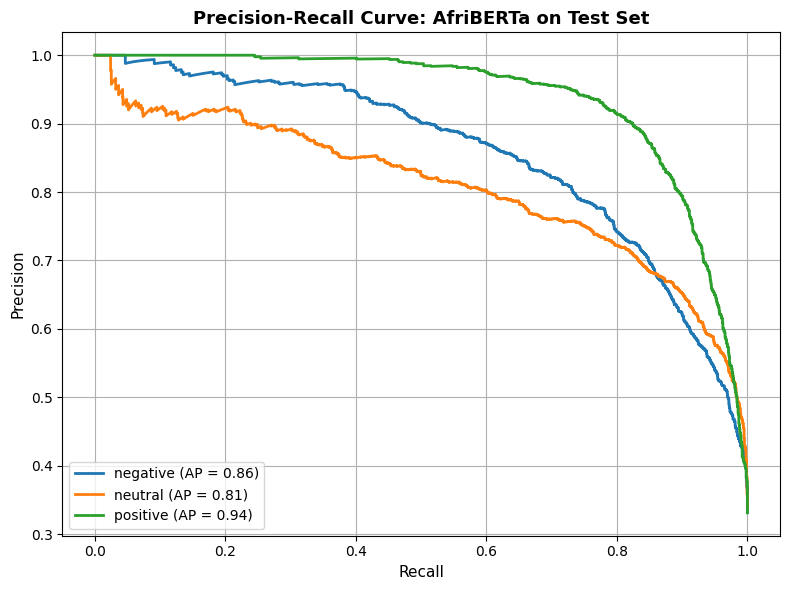

In [ ]:
# Plot the Precision-Recall curve on the Test Set
plot_precision_recall_curve(
    y_true=y_test,
    y_probs=transformer_probabilities,
    class_names=class_names,
    title="Precision-Recall Curve: AfriBERTa on Test Set"
)

#### Confusion Matrix

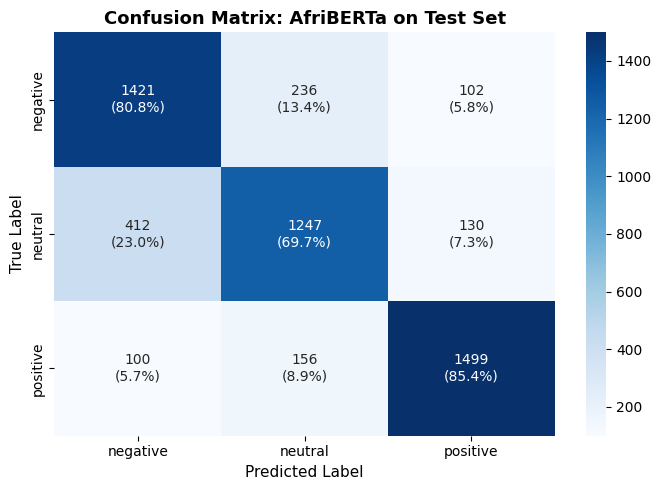

In [ ]:
# Plot the Confusion Matrix on the Test Set
plot_confusion_matrix(
    y_true=y_test,
    y_pred=transformer_test_preds,
    class_names=class_names,
    title="Confusion Matrix: AfriBERTa on Test Set"
)

#### Save the AfriBERTa Model

In [ ]:
# Save the model and tokenizer to a local directory
save_directory = "./afriberta_model"

trainer.save_model(save_directory)
tokenizer.save_pretrained(save_directory)

# Calculate total size of the saved directory
total_size_bytes = 0
for dirpath, _, filenames in os.walk(save_directory):
    for f in filenames:
        fp = os.path.join(dirpath, f)
        total_size_bytes += os.path.getsize(fp)

total_size_mb = total_size_bytes / (1024 * 1024)
print(f"Model and tokenizer successfully saved to {save_directory}!")
print(f"Total saved model size: {total_size_mb:.2f} MB")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model and tokenizer successfully saved to ./afriberta_model!
Total saved model size: 484.02 MB


#### AfriBERTa Transformer Test Set Insights

* **Outstanding Generalization and SOTA Performance:** AfriBERTa achieves an excellent test set accuracy of **78.58%** and a weighted F1-score of **78.54%**, Slightly worse than its validation performance.
* **Exceptional Class Separability (PR & AUC):** The model obtains outstanding Average Precision (AP) scores across all classes: **0.94** for positive tweets, **0.86** for negative tweets, and **0.81** for neutral tweets. The sharp thresholding curves confirm that AfriBERTa's probability outputs are highly confident and reliable.
* **Strong Performance on Extreme Ends:** The model displays a strong performance on identifying negative and positive classes with a recall of **80.8** and **85.4** respectively.

## **Conclusion**

When transitioning the sentiment analysis system from development to a production environment, engineering constraints such as inference latency, memory footprint, hosting cost, and hardware availability must be balanced against absolute predictive accuracy.

Below is a structured matrix comparing our two champion models across key operational dimensions:

| Deployment Dimension | Classic Champion: Hybrid TF-IDF + SVM | Deep Learning Champion: AfriBERTa | Strategic Trade-off Analysis |
| :--- | :---: | :---: | :--- |
| **Accuracy** | **78.01%** | **78.58%** | AfriBERTa delivers a slight performance boost, particularly in resolving difficult negative sentiment boundaries. |
| **Model Disk Size** | **~6 MB** | **~484 MB** | TF-IDF + SVM is **~80x smaller**, making it highly suitable for serverless functions, Edge, or mobile deployment. |
| **Memory Usage (RAM)** | **< 200 MB** | **>= 1.5 GB** | TF-IDF + SVM has a minimal memory footprint, allowing sidecar deployment on cheap, shared-instance servers. |
| **Hardware Dependency**| Standard CPU | NVIDIA GPU (Recommended for real-time scaling) | SVM is entirely hardware-agnostic. AfriBERTa scaling on CPUs will incur substantial latency penalties or require quantization. |
| **Operational Complexity**| Extremely Low (Standard python dependencies) | Medium (Requires PyTorch, Tokenizers, GPU drivers) | Classic ML has a vastly simplified pipeline, minimizing dependency drift and dependency management overhead. |

**Final Decision:**
We will deploy the Hybrid TF-IDF+SVM. Despite AfriBERTa's superior accuracy, the SVM's low latency, tiny footprint, and cheap CPU hosting make it the optimal choice.

## **References**

[1] K. Ogueji, Y. Zhu, and J. Lin, "Small data? No problem! Exploring the viability of pretrained multilingual language models for low-resourced languages," in *Proc. 1st Workshop Multilingual Representation Learning*, 2021, pp. 116–126.

[2] S. H. Muhammad, I. Abdulmumin, A. A. Ayele, N. Ousidhoum, D. I. Adelani, S. M. Yimam, I. S. Ahmad, M. Beloucif, S. M. Mohammad, S. Ruder, et al., "AfriSenti: A Twitter sentiment analysis benchmark for African languages," in *Proc. Conf. Empirical Methods Natural Lang. Process. (EMNLP)*, 2023, pp. 13968–13981.